# Gerencia y Almacenamiento en Big Data — Proyecto Final
## Rendimiento en powerlifting: pipeline de Big Data con Machine Learning sobre el dataset OpenIPF

**Enlace al video de sustentación:**

**Estudiante:** Oscar Alejandro Morales Calderón

**Programa:** Ingeniería de Sistemas — Fundación Universitaria Los Libertadores

---

El notebook sigue las fases de CRISP-DM:

1. Business Understanding
2. Decisión de arquitectura (pandas o Spark)
3. Data Understanding
4. Data Preparation (ETL)
5. Análisis exploratorio y agregaciones OLAP
6. Modeling
7. Evaluation
8. Deployment: MongoDB, reporte PDF y archivos para el dashboard

Se ejecuta dentro del contenedor `procesamiento`. Lee el CSV de `data/raw/` y deja listos el Parquet, el modelo, el documento de MongoDB y el PDF que usa el dashboard.

---
# 1. Business Understanding

## 1.1 Dataset

| Dato | Valor |
|---|---|
| Nombre | OpenIPF (subconjunto de OpenPowerlifting) |
| Fuente | Proyecto OpenPowerlifting, datos de dominio público |
| URL | https://openpowerlifting.gitlab.io/opl-csv/bulk-csv.html |
| Archivo | `openipf-2026-11-07-f93a530c.csv` |
| Fecha de descarga | 7 de noviembre de 2026 |
| Periodo | 1966 a noviembre de 2026 |
| Contenido | Resultados de competencias de la Federación Internacional de Powerlifting (IPF) y sus afiliadas |

El número de filas, columnas y el peso en disco y en memoria se miden en la sección 2.

**Por qué se eligió:**

- Es real y público: lo mantiene el proyecto OpenPowerlifting a partir de las planillas oficiales de cada competencia.
- Tiene más de 1,5 millones de registros, por encima del mínimo de 500.000.
- No viene limpio: tiene nulos, duplicados, edades imposibles y categorías escritas de varias formas.
- Sirve para Machine Learning: tiene una variable numérica clara para predecir (el total levantado) y variables que se conocen antes de competir.

## 1.2 Contexto

El powerlifting es un deporte de fuerza con tres levantamientos: **sentadilla**, **press de banca** y **peso muerto**. Cada atleta tiene tres intentos por levantamiento. El mejor intento válido de cada uno se suma y da el **total**.

| Término | Significado |
|---|---|
| `Event` | Levantamientos en los que compitió. `SBD` es la competencia completa; `B` es solo banca. |
| `Equipment` | `Raw`: sin equipo de soporte. `Single-ply`: con traje y camisa rígidos que ayudan a levantar más. |
| `TotalKg` | Suma de los tres mejores intentos. |
| `Dots` | Puntaje que ajusta el total según peso corporal y sexo. Permite comparar atletas de categorías distintas. |
| `Place` | Puesto. `DQ` descalificado, `NS` no se presentó, `DD` descalificado por dopaje, `G` invitado. |

## 1.3 Pregunta de negocio

**¿Qué factores explican el rendimiento de un atleta de powerlifting y se puede estimar su total antes de que compita?**

Una federación o un entrenador puede usar la respuesta para ubicar a un atleta frente a sus pares, proyectar marcas y planear categorías.

Preguntas específicas:

- **P1.** ¿Cómo ha cambiado la participación de hombres y mujeres desde el año 2000?
- **P2.** ¿A qué edad se alcanza el mejor rendimiento y cuánto cae después?
- **P3.** ¿Cuánto peso adicional permite levantar el equipo Single-ply frente a Raw en cada levantamiento?
- **P4.** ¿Con qué error se puede estimar el total de un atleta usando solo datos conocidos antes de competir, y qué variables pesan más?

## 1.4 Tarea de Machine Learning

- **Tarea:** regresión. Se predice `TotalKg` (kilos).
- **Variables de entrada:** sexo, equipo, edad, peso corporal, año, competencias previas y años de experiencia.
- **Línea base:** predecir siempre el promedio del total.
- **Criterio de éxito:** que el mejor modelo reduzca el error absoluto medio (MAE) de la línea base en al menos **40 %** y tenga un R² de al menos **0,70** en datos de prueba.

---
# 2. Decisión de arquitectura: pandas o Spark

## 2.1 Configuración del entorno

In [1]:
import os
import sys
import time
import json
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt

# Carpeta raíz del proyecto (el notebook está en notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

DIR_RAW       = RAIZ / 'data' / 'raw'
DIR_PROCESSED = RAIZ / 'data' / 'processed'
DIR_MODELS    = RAIZ / 'models'
DIR_REPORTS   = RAIZ / 'reports'
DIR_FIGURAS   = DIR_REPORTS / 'figuras'

for carpeta in [DIR_PROCESSED, DIR_MODELS, DIR_FIGURAS]:
    carpeta.mkdir(parents=True, exist_ok=True)

# Los scripts de src/ se usan para generar el PDF
sys.path.append(str(RAIZ / 'src'))

# Colores de la paleta Okabe-Ito (se distinguen con daltonismo)
AZUL    = '#0072B2'
NARANJA = '#E69F00'
VERDE   = '#009E73'
GRIS    = '#7f7f7f'
GRIS_CLARO = '#b5b5b5'
TEXTO   = '#222222'
GRID    = '#e5e5e5'

COLOR_SEXO = {'Hombres': AZUL, 'Mujeres': NARANJA}

plt.rcParams.update({
    'figure.dpi': 100,
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': GRIS,
    'axes.labelcolor': TEXTO,
    'xtick.color': TEXTO,
    'ytick.color': TEXTO,
})

figuras_generadas = []   # se guarda después en MongoDB


def miles(valor):
    """Número entero con punto de miles: 1535307 -> '1.535.307'."""
    return f'{valor:,.0f}'.replace(',', '.')


def coma(valor, decimales=1):
    """Número con coma decimal: 12.5 -> '12,5'."""
    return f'{valor:.{decimales}f}'.replace('.', ',')


def poner_titulo(ax, titulo, subtitulo):
    """Título con el hallazgo y subtítulo con el detalle, alineados a la izquierda."""
    ax.set_title(titulo, loc='left', fontsize=14, fontweight='bold', color=TEXTO, pad=30)
    ax.annotate(subtitulo, xy=(0, 1), xycoords='axes fraction', xytext=(0, 10),
                textcoords='offset points', fontsize=10.5, color=GRIS)


def eje_con_coma(eje):
    """Muestra los números del eje con coma decimal."""
    eje.set_major_formatter(lambda valor, posicion: coma(valor))


def guardar(fig, nombre, descripcion):
    """Guarda la figura en reports/figuras/, la registra y la muestra."""
    fig.savefig(DIR_FIGURAS / nombre, dpi=150, bbox_inches='tight')
    figuras_generadas.append({'archivo': nombre, 'descripcion': descripcion})
    plt.show()


print('Entorno listo. Carpeta del proyecto:', RAIZ.name)

Entorno listo. Carpeta del proyecto: Morales_Oscar_BigData_ProyectoFinal


## 2.2 Mediciones

Para decidir entre pandas y Spark se mide el tamaño real del archivo, los recursos de la máquina y cuánta memoria ocupan los datos con dos formas de lectura:

- **Lectura por defecto:** pandas guarda cada texto completo en cada fila.
- **Lectura optimizada:** las columnas de texto se leen como `category`. Cada texto distinto se guarda una sola vez y las filas guardan un número pequeño que lo señala.

La comparación de memoria se hace con las primeras 200.000 filas, para no cargar dos veces el archivo completo.

In [2]:
# Archivo de datos: el CSV de OpenIPF que esté en data/raw/
archivos = sorted(glob.glob(str(DIR_RAW / 'openipf-*.csv')))
assert archivos, 'No hay CSV en data/raw/. Ejecute primero: python src/descargar_datos.py'
RUTA_CSV = archivos[-1]

peso_disco_mb = os.path.getsize(RUTA_CSV) / 1024**2
ram_total_gb = psutil.virtual_memory().total / 1024**3
ram_libre_gb = psutil.virtual_memory().available / 1024**3
nucleos = psutil.cpu_count()

print('Archivo:', os.path.basename(RUTA_CSV))
print('Peso en disco:', miles(peso_disco_mb), 'MB')
print('RAM total:', coma(ram_total_gb), 'GB | disponible:', coma(ram_libre_gb), 'GB')
print('Núcleos:', nucleos)

Archivo: openipf-2026-11-07-f93a530c.csv
Peso en disco: 315 MB
RAM total: 7,8 GB | disponible: 7,3 GB
Núcleos: 2


In [3]:
columnas_texto = ['Name', 'Sex', 'Event', 'Equipment', 'AgeClass', 'BirthYearClass', 'Division',
                  'WeightClassKg', 'Place', 'Tested', 'Country', 'State', 'Federation',
                  'ParentFederation', 'MeetCountry', 'MeetState', 'MeetTown', 'MeetName', 'Sanctioned']
tipos = {columna: 'category' for columna in columnas_texto}

# Comparación de memoria con una muestra de 200.000 filas
muestra_defecto = pd.read_csv(RUTA_CSV, nrows=200_000, low_memory=False)
muestra_optima  = pd.read_csv(RUTA_CSV, nrows=200_000, dtype=tipos, low_memory=False)

mb_defecto = muestra_defecto.memory_usage(deep=True).sum() / 1024**2
mb_optima  = muestra_optima.memory_usage(deep=True).sum() / 1024**2
del muestra_defecto, muestra_optima

print('Memoria de 200.000 filas, lectura por defecto:', coma(mb_defecto), 'MB')
print('Memoria de 200.000 filas, lectura optimizada: ', coma(mb_optima), 'MB')
print('Reducción:', coma((1 - mb_optima / mb_defecto) * 100), '%')

Memoria de 200.000 filas, lectura por defecto: 87,1 MB
Memoria de 200.000 filas, lectura optimizada:  45,4 MB
Reducción: 47,8 %


In [4]:
# Carga completa con tipos optimizados, midiendo el tiempo
inicio = time.time()
df = pd.read_csv(RUTA_CSV, dtype=tipos, low_memory=False)
segundos_carga = time.time() - inicio

filas_crudo, columnas_crudo = df.shape
memoria_mb = df.memory_usage(deep=True).sum() / 1024**2
memoria_defecto_estimada_mb = mb_defecto / 200_000 * filas_crudo

print('Filas:   ', miles(filas_crudo))
print('Columnas:', columnas_crudo)
print('Tiempo de carga:', coma(segundos_carga), 's')
print('Memoria con tipos optimizados:', miles(memoria_mb), 'MB')
print('Memoria estimada con lectura por defecto:', miles(memoria_defecto_estimada_mb), 'MB')
print('Los datos ocupan el', coma(memoria_mb / 1024 / ram_total_gb * 100), '% de la RAM total')

Filas:    1.535.307
Columnas: 42
Tiempo de carga: 8,6 s
Memoria con tipos optimizados: 355 MB
Memoria estimada con lectura por defecto: 669 MB
Los datos ocupan el 4,4 % de la RAM total


## 2.3 Decisión: pandas

Con la versión del 7 de noviembre de 2026 del dataset, las mediciones de arriba dan:

| Medida | Valor |
|---|---|
| Filas | 1.535.307 |
| Peso en disco | 315 MB |
| Memoria con lectura por defecto (estimada) | cerca de 670 MB |
| Memoria con tipos optimizados | cerca de 355 MB |
| Tiempo de carga del CSV completo | unos segundos |

La RAM, los núcleos y el tiempo exactos dependen de la máquina y quedan impresos en las celdas anteriores.

**Se elige pandas** por estas razones:

- **Los datos caben en memoria.** Ocupan unos 355 MB, una fracción pequeña de la RAM disponible. Spark se justifica cuando los datos no caben en la memoria de una sola máquina o cuando hay un clúster para repartir el trabajo. Ninguna de las dos cosas pasa aquí.
- **Spark en una sola máquina agrega costo y no capacidad.** Hay que arrancar la JVM, planificar cada consulta y pasar datos entre Python y Java. En la Actividad 4, con un volumen parecido, ese costo fijo pesó más que el beneficio.
- **Menos piezas en Docker.** Con pandas el contenedor de procesamiento solo necesita Python. Con Spark necesitaría además Java y más memoria reservada.
- **El modelo se entrena con scikit-learn**, que trabaja directamente con tablas de pandas.

**Técnicas usadas para manejar el volumen con pandas:**

1. **Tipos optimizados:** las 19 columnas de texto se leen como `category`. La memoria baja casi a la mitad.
2. **Selección de columnas:** después de explorar, se conservan 15 de las 42 columnas y se libera la tabla original.
3. **Formato Parquet:** el dataset limpio se guarda en Parquet, que es columnar y comprimido. Pesa cerca de 35 MB frente a los 315 MB del CSV, y el dashboard lo lee en menos de un segundo.

**Cuándo habría que cambiar a Spark:** si se usara el dataset completo de OpenPowerlifting con todas las federaciones y sus intentos (varias veces más grande) junto con otras fuentes, o si los datos dejaran de caber en la memoria del contenedor.

---
# 3. Data Understanding

## 3.1 Estructura

In [5]:
df.head()

,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName,Sanctioned
0,Mihaela Osmajić,F,B,Raw,19.0,18-19,19-23,J,52.0,52,...,Serbia,NaN,PLSS,IPF,2019-11-02,Serbia,NaN,NaN,Kup Vojvodine,Yes
1,Srđana Glušac,F,B,Raw,NaN,NaN,NaN,J,63.0,63,...,Serbia,NaN,PLSS,IPF,2019-11-02,Serbia,NaN,NaN,Kup Vojvodine,Yes
2,Marija Polomac,F,B,Raw,46.0,45-49,40-49,O,63.0,63,...,Serbia,NaN,PLSS,IPF,2019-11-02,Serbia,NaN,NaN,Kup Vojvodine,Yes
3,Biljana Erić,F,B,Raw,NaN,NaN,NaN,O,72.0,72,...,Serbia,NaN,PLSS,IPF,2019-11-02,Serbia,NaN,NaN,Kup Vojvodine,Yes
4,Milanka Cicmil,F,B,Raw,32.0,24-34,24-39,O,72.0,72,...,Serbia,NaN,PLSS,IPF,2019-11-02,Serbia,NaN,NaN,Kup Vojvodine,Yes


In [6]:
# Tipo de dato de cada columna
df.dtypes.to_frame('tipo').T

,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName,Sanctioned
tipo,category,category,category,category,float64,category,category,category,float64,category,...,category,category,category,category,str,category,category,category,category,category


Las 42 columnas se agrupan así:

- **Atleta:** `Name`, `Sex`, `Age`, `AgeClass`, `BirthYearClass`, `Country`, `State`.
- **Categoría:** `Event`, `Equipment`, `Division`, `BodyweightKg`, `WeightClassKg`.
- **Intentos:** `Squat1Kg` … `Deadlift4Kg`. Un valor negativo es un intento fallido.
- **Resultado:** `Best3SquatKg`, `Best3BenchKg`, `Best3DeadliftKg`, `TotalKg`, `Place`.
- **Puntajes:** `Dots`, `Wilks`, `Glossbrenner`, `Goodlift`.
- **Competencia:** `Federation`, `ParentFederation`, `Date`, `MeetCountry`, `MeetState`, `MeetTown`, `MeetName`, `Tested`, `Sanctioned`.

Cada fila es **una participación** de un atleta en una competencia.

## 3.2 Nulos

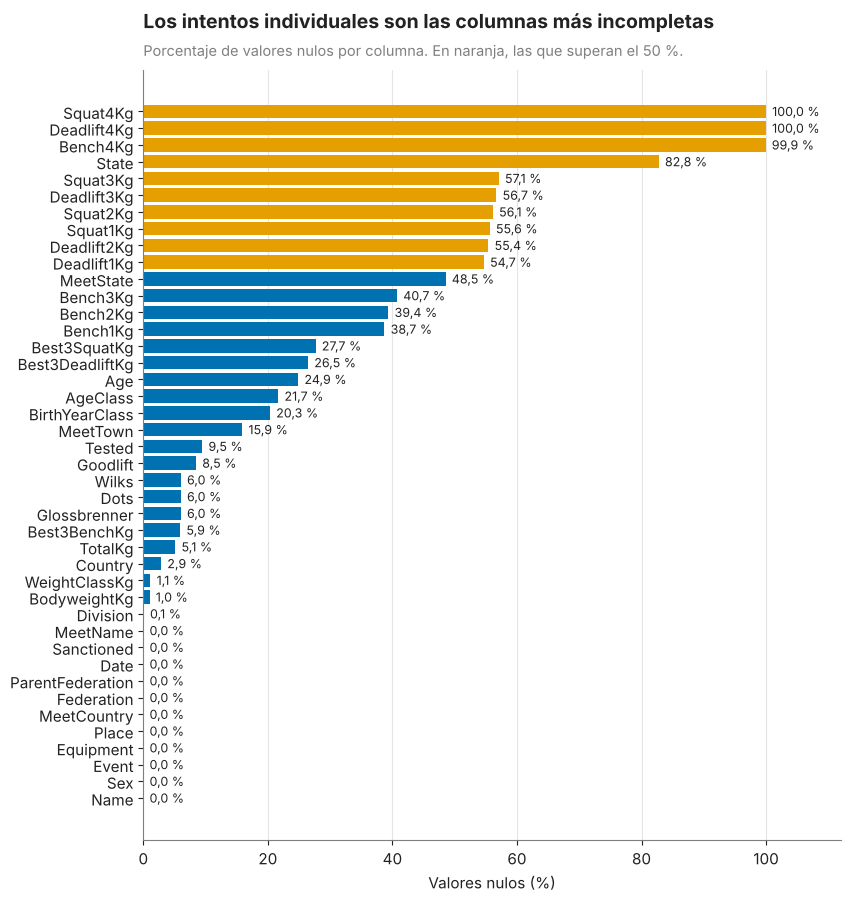

In [7]:
nulos = (df.isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 10))
colores = [NARANJA if valor > 50 else AZUL for valor in nulos]
ax.barh(nulos.index, nulos.values, color=colores)
for y, valor in enumerate(nulos.values):
    ax.text(valor + 1, y, coma(valor) + ' %', va='center', fontsize=9, color=TEXTO)
ax.set_xlim(0, 112)
ax.set_xlabel('Valores nulos (%)')
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
poner_titulo(ax, 'Los intentos individuales son las columnas más incompletas',
             'Porcentaje de valores nulos por columna. En naranja, las que superan el 50 %.')
guardar(fig, 'fig01_nulos.png', 'Porcentaje de valores nulos por columna')

## 3.3 Duplicados, fechas y valores únicos

In [8]:
duplicados = int(df.duplicated().sum())
fecha_min, fecha_max = df['Date'].min(), df['Date'].max()

print('Filas duplicadas exactas:', miles(duplicados))
print('Fecha más antigua:', fecha_min)
print('Fecha más reciente:', fecha_max)
print('Atletas distintos (por nombre):', miles(df['Name'].nunique()))
print('Federaciones:', df['Federation'].nunique())
print('Países de los atletas:', df['Country'].nunique())
print('Valores de ParentFederation:', list(df['ParentFederation'].unique()))

Filas duplicadas exactas: 531
Fecha más antigua: 1966-02-27
Fecha más reciente: 2026-11-01
Atletas distintos (por nombre): 442.002
Federaciones: 118
Países de los atletas: 163
Valores de ParentFederation: ['IPF']


## 3.4 Columnas categóricas

In [9]:
for columna in ['Sex', 'Event', 'Equipment']:
    conteo = df[columna].value_counts()
    tabla = pd.DataFrame({'filas': conteo, '%': (conteo / len(df) * 100).round(2)})
    print(f'--- {columna} ---')
    print(tabla.to_string())
    print()

# Valores de Place que no son un puesto numérico
puestos = df['Place'].astype(str)
print('--- Place no numérico ---')
print(puestos[~puestos.str.isdigit()].value_counts().to_string())

--- Sex ---
       filas      %
Sex                
M    1137186  74.07
F     398113  25.93
Mx         8   0.00

--- Event ---
         filas      %
Event                
SBD    1142032  74.38
B       353857  23.05
D        26777   1.74
BD        8247   0.54
S         2479   0.16
SB        1650   0.11
SD         265   0.02

--- Equipment ---
             filas      %
Equipment                
Raw         825468  53.77
Single-ply  706930  46.04
Wraps         2909   0.19

--- Place no numérico ---


Place
DQ    75041
G      9713
NS     2648
DD     1142


In [10]:
# La misma división aparece escrita de varias formas
divisiones = df['Division'].astype(str)
print('Valores distintos de Division:', df['Division'].nunique())
print()
print('Formas de escribir la división juvenil (las 8 más frecuentes):')
print(divisiones[divisiones.str.contains('jun|jr', case=False)].value_counts().head(8).to_string())

Valores distintos de Division: 1166

Formas de escribir la división juvenil (las 8 más frecuentes):
Division
Juniors          139985
Sub-Juniors       75476
MR-Jr             23313
Junior            15304
Juniors 19-23     10512
FR-Jr              8855
Sub-Junior         4724
M-Jr               3497


## 3.5 Estadísticas descriptivas (antes de limpiar)

In [11]:
numericas = ['Age', 'BodyweightKg', 'Best3SquatKg', 'Best3BenchKg', 'Best3DeadliftKg', 'TotalKg', 'Dots']
estadisticas_crudo = df[numericas].describe().round(1)
estadisticas_crudo

,Age,BodyweightKg,Best3SquatKg,Best3BenchKg,Best3DeadliftKg,TotalKg,Dots
count,1153452.0,1519889.0,1110538.0,1444463.0,1129150.0,1456476.0,1442940.0
mean,29.5,82.2,179.6,120.0,198.3,403.9,297.4
std,13.1,21.3,67.7,50.8,60.8,212.5,134.6
min,3.5,16.0,-440.0,-335.0,-400.0,1.0,0.6
25%,19.5,66.6,130.0,80.0,150.0,215.0,167.3
50%,25.0,81.1,177.5,117.9,200.0,405.0,330.7
75%,36.5,93.9,225.0,152.5,242.5,570.0,396.4
max,96.5,275.0,515.0,455.0,430.0,1296.0,709.2


In [12]:
# Valores sospechosos
edades_imposibles = int(((df['Age'] < 8) | (df['Age'] > 90)).sum())
edades_medio_anio = int((df['Age'] % 1 == 0.5).sum())
mejores_negativos = int((df[['Best3SquatKg', 'Best3BenchKg', 'Best3DeadliftKg']] < 0).any(axis=1).sum())
sin_resultado = int(df['Place'].astype(str).isin(['DQ', 'NS', 'DD']).sum())

print('Edades menores de 8 o mayores de 90 años:', miles(edades_imposibles))
print('Edades terminadas en ,5 (aproximadas):', miles(edades_medio_anio))
print('Filas con un mejor levantamiento negativo:', miles(mejores_negativos))
print('Filas sin resultado válido (DQ, NS, DD):', miles(sin_resultado))

# Ejemplo de edades imposibles
df.loc[df['Age'] < 5, ['Name', 'Age', 'BodyweightKg', 'Event', 'TotalKg', 'Division', 'Date']]

Edades menores de 8 o mayores de 90 años: 106
Edades terminadas en ,5 (aproximadas): 784.662
Filas con un mejor levantamiento negativo: 4.011
Filas sin resultado válido (DQ, NS, DD): 78.831


,Name,Age,BodyweightKg,Event,TotalKg,Division,Date
175799,Sergey Vislotskiy,3.5,28.0,B,4.5,Sub-Juniors,2009-07-11
226889,Sergey Vislotskiy,4.5,32.0,B,9.0,Sub-Juniors,2010-07-11
462747,Gabriela Martinez Koch,3.5,103.6,SBD,327.5,Sub-Juniors,2025-11-08
678733,Andriy Nikolaenko,4.5,52.0,SBD,260.0,Open,2001-06-02
1150595,Gábor Putyera,3.5,89.3,B,157.5,Open,2017-03-11


## 3.6 Problemas de calidad detectados

| # | Problema | Evidencia | Técnica ETL que lo resuelve |
|---|---|---|---|
| 1 | Filas duplicadas exactas | Sección 3.3 | Limpieza |
| 2 | Columnas casi vacías (`Squat4Kg`, `Bench4Kg`, `Deadlift4Kg`, `State`) | Sección 3.2 | Limpieza: no se conservan |
| 3 | Sexo `Mx` con muy pocas filas | Sección 3.4 | Limpieza |
| 4 | Edades imposibles (3 años con 103 kg de peso corporal) | Sección 3.5 | Limpieza: se dejan como dato faltante |
| 5 | Filas sin resultado válido (`DQ`, `NS`, `DD`) y mejores levantamientos negativos | Secciones 3.4 y 3.5 | Limpieza: se marcan y no entran al análisis de rendimiento |
| 6 | `Date` está como texto | Sección 3.1 | Normalización |
| 7 | Edades terminadas en ,5 cuando solo se conoce el año de nacimiento | Sección 3.5 | Normalización: se toma la parte entera |
| 8 | Códigos en inglés (`M`, `F`) y nombres de columnas en inglés | Sección 3.1 | Normalización |
| 9 | Países históricos (`USSR`, `West Germany`, `Yugoslavia`) y países del Reino Unido separados | Sección 4.3 | Normalización y enriquecimiento |
| 10 | `Division` escrita de muchas formas | Sección 3.4 | No se usa: la edad da la misma información de forma consistente |
| 11 | `ParentFederation` tiene un solo valor | Sección 3.3 | Limpieza: no se conserva |

---
# 4. Data Preparation (ETL)

Se aplican las cuatro técnicas en este orden: limpieza, normalización, enriquecimiento y agregación. Cada paso guarda el número de filas antes y después en `registro_etl`.

In [13]:
registro_etl = []   # una fila por cada paso del ETL


def registrar(tecnica, paso, antes, despues, detalle=''):
    """Guarda el conteo antes/después de un paso del ETL."""
    registro_etl.append({'tecnica': tecnica, 'paso': paso, 'antes': int(antes),
                         'despues': int(despues), 'cambio': int(despues - antes), 'detalle': detalle})
    print(f'[{tecnica}] {paso}: {miles(antes)} -> {miles(despues)} ({miles(despues - antes)}) {detalle}')

## 4.1 Limpieza

In [14]:
# 1. Filas duplicadas exactas (se buscan con todas las columnas)
antes = len(df)
df_limpio = df.drop_duplicates()
registrar('Limpieza', 'Eliminar filas duplicadas', antes, len(df_limpio), 'filas')

# 2. Columnas que no se usan o no aportan información
columnas_utiles = ['Name', 'Sex', 'Event', 'Equipment', 'Age', 'BodyweightKg',
                   'Best3SquatKg', 'Best3BenchKg', 'Best3DeadliftKg', 'TotalKg',
                   'Place', 'Dots', 'Country', 'Federation', 'Date']
antes = df_limpio.shape[1]
df_limpio = df_limpio[columnas_utiles].copy()
registrar('Limpieza', 'Conservar solo las columnas útiles', antes, df_limpio.shape[1], 'columnas')

# Se libera la tabla original: ya no se necesita
del df

# 3. Solo sexo M y F
antes = len(df_limpio)
df_limpio = df_limpio[df_limpio['Sex'].isin(['M', 'F'])]
registrar('Limpieza', 'Quitar sexo Mx', antes, len(df_limpio), 'filas')

# 4. Edades imposibles: se dejan como dato faltante (la fila se conserva)
antes = df_limpio['Age'].notna().sum()
df_limpio.loc[(df_limpio['Age'] < 8) | (df_limpio['Age'] > 90), 'Age'] = np.nan
registrar('Limpieza', 'Edades fuera de 8 a 90 años pasan a nulo', antes, df_limpio['Age'].notna().sum(), 'edades con dato')

# 5. Mejores levantamientos negativos (los tres intentos fallidos): se dejan como dato faltante
for columna in ['Best3SquatKg', 'Best3BenchKg', 'Best3DeadliftKg']:
    antes = df_limpio[columna].notna().sum()
    df_limpio.loc[df_limpio[columna] <= 0, columna] = np.nan
    registrar('Limpieza', f'{columna} negativo pasa a nulo', antes, df_limpio[columna].notna().sum(), 'valores con dato')

[Limpieza] Eliminar filas duplicadas: 1.535.307 -> 1.534.776 (-531) filas
[Limpieza] Conservar solo las columnas útiles: 42 -> 15 (-27) columnas
[Limpieza] Quitar sexo Mx: 1.534.776 -> 1.534.768 (-8) filas
[Limpieza] Edades fuera de 8 a 90 años pasan a nulo: 1.152.996 -> 1.152.890 (-106) edades con dato
[Limpieza] Best3SquatKg negativo pasa a nulo: 1.110.205 -> 1.108.175 (-2.030) valores con dato
[Limpieza] Best3BenchKg negativo pasa a nulo: 1.443.973 -> 1.442.564 (-1.409) valores con dato


[Limpieza] Best3DeadliftKg negativo pasa a nulo: 1.128.784 -> 1.128.061 (-723) valores con dato


## 4.2 Normalización

In [15]:
# 1. Fecha: de texto a fecha
print('Tipo de Date antes:', df_limpio['Date'].dtype)
df_limpio['Date'] = pd.to_datetime(df_limpio['Date'], format='%Y-%m-%d')
print('Tipo de Date después:', df_limpio['Date'].dtype)
registrar('Normalización', 'Date de texto a fecha', len(df_limpio), len(df_limpio), 'filas (cambia el tipo)')

# 2. Edad en años cumplidos
antes = int((df_limpio['Age'] % 1 == 0.5).sum())
df_limpio['Age'] = np.floor(df_limpio['Age'])
registrar('Normalización', 'Edades con ,5 a años cumplidos', antes, int((df_limpio['Age'] % 1 == 0.5).sum()), 'edades con ,5')

# 3. Códigos de sexo a etiquetas en español
print('Valores de Sex antes:', sorted(df_limpio['Sex'].astype(str).unique()))
df_limpio['Sex'] = df_limpio['Sex'].astype(str).map({'M': 'Hombres', 'F': 'Mujeres'})
print('Valores de Sex después:', sorted(df_limpio['Sex'].unique()))
registrar('Normalización', 'Sexo M/F a Hombres/Mujeres', len(df_limpio), len(df_limpio), 'filas (cambia la etiqueta)')

# 4. Puesto: se separa el resultado válido del puesto numérico
puesto = df_limpio['Place'].astype(str)
df_limpio['resultado_valido'] = ~puesto.isin(['DQ', 'NS', 'DD'])
registrar('Normalización', 'Place a columna resultado_valido', len(df_limpio), int(df_limpio['resultado_valido'].sum()), 'filas con resultado válido')

# 5. Países históricos o divididos se unifican con su nombre actual
equivalencias_pais = {'West Germany': 'Germany', 'USSR': 'Russia', 'Czechoslovakia': 'Czechia',
                      'Serbia and Montenegro': 'Serbia', 'Yugoslavia': 'Serbia',
                      'England': 'UK', 'Scotland': 'UK', 'Wales': 'UK', 'N.Ireland': 'UK',
                      'Tahiti': 'French Polynesia', 'Netherlands Antilles': 'Netherlands'}
antes = df_limpio['Country'].nunique()
df_limpio['Country'] = df_limpio['Country'].astype(object).replace(equivalencias_pais)
registrar('Normalización', 'Unificar países históricos', antes, df_limpio['Country'].nunique(), 'países distintos')

# 6. Nombres de columnas en español
nombres_columnas = {'Name': 'nombre', 'Sex': 'sexo', 'Event': 'evento', 'Equipment': 'equipo', 'Age': 'edad',
                    'BodyweightKg': 'peso_corporal_kg', 'Best3SquatKg': 'sentadilla_kg', 'Best3BenchKg': 'banca_kg',
                    'Best3DeadliftKg': 'peso_muerto_kg', 'TotalKg': 'total_kg', 'Place': 'puesto', 'Dots': 'dots',
                    'Country': 'pais', 'Federation': 'federacion', 'Date': 'fecha'}
df_limpio = df_limpio.rename(columns=nombres_columnas)

for columna in ['evento', 'equipo', 'puesto', 'federacion']:
    df_limpio[columna] = df_limpio[columna].astype(str)

print()
print('Columnas:', list(df_limpio.columns))

Tipo de Date antes: str
Tipo de Date después: datetime64[us]
[Normalización] Date de texto a fecha: 1.534.768 -> 1.534.768 (0) filas (cambia el tipo)


[Normalización] Edades con ,5 a años cumplidos: 784.240 -> 0 (-784.240) edades con ,5
Valores de Sex antes: ['F', 'M']


Valores de Sex después: ['Hombres', 'Mujeres']
[Normalización] Sexo M/F a Hombres/Mujeres: 1.534.768 -> 1.534.768 (0) filas (cambia la etiqueta)
[Normalización] Place a columna resultado_valido: 1.534.768 -> 1.456.005 (-78.763) filas con resultado válido


[Normalización] Unificar países históricos: 163 -> 152 (-11) países distintos



Columnas: ['nombre', 'sexo', 'evento', 'equipo', 'edad', 'peso_corporal_kg', 'sentadilla_kg', 'banca_kg', 'peso_muerto_kg', 'total_kg', 'puesto', 'dots', 'pais', 'federacion', 'fecha', 'resultado_valido']


## 4.3 Enriquecimiento

Se agregan columnas que no venían en el archivo:

| Columna nueva | Cómo se calcula | Para qué sirve |
|---|---|---|
| `anio` | Año de la fecha | Evolución en el tiempo (P1) y variable del modelo |
| `continente` | Tabla externa país → continente | Filtro del dashboard y drill-down continente → país |
| `grupo_edad` | Rangos de edad | Agregaciones OLAP |
| `competencias_previas` | Número de competencias anteriores del mismo atleta | Variable del modelo: mide experiencia |
| `anios_experiencia` | Años desde su primera competencia registrada | Variable del modelo: mide experiencia |
| `fuerza_relativa` | Total ÷ peso corporal | Comparar atletas de distinto peso (P3) |

`competencias_previas` y `anios_experiencia` son las **dos variables derivadas para el modelo**. Se calculan solo con competencias anteriores a la fecha de cada fila.

In [16]:
# Año
df_limpio['anio'] = df_limpio['fecha'].dt.year
registrar('Enriquecimiento', 'Columna anio', df_limpio.shape[1] - 1, df_limpio.shape[1], 'columnas')

# Continente (tabla externa)
continentes = {
    'América': ['USA', 'Canada', 'Mexico', 'Argentina', 'Brazil', 'Colombia', 'Chile', 'Peru', 'Ecuador', 'Venezuela',
                'Uruguay', 'Paraguay', 'Bolivia', 'Costa Rica', 'Panama', 'Guatemala', 'Honduras', 'El Salvador',
                'Nicaragua', 'Belize', 'Puerto Rico', 'Dominican Republic', 'Jamaica', 'Bahamas', 'Bermuda',
                'Trinidad and Tobago', 'Guyana', 'Suriname', 'Aruba', 'Cayman Islands', 'British Virgin Islands',
                'US Virgin Islands'],
    'Europa': ['Russia', 'Germany', 'UK', 'Norway', 'France', 'Finland', 'Ukraine', 'Sweden', 'Poland', 'Italy', 'Spain',
               'Netherlands', 'Belgium', 'Austria', 'Switzerland', 'Denmark', 'Ireland', 'Iceland', 'Czechia', 'Slovakia',
               'Hungary', 'Romania', 'Bulgaria', 'Greece', 'Portugal', 'Serbia', 'Croatia', 'Slovenia',
               'Bosnia and Herzegovina', 'North Macedonia', 'Belarus', 'Estonia', 'Latvia', 'Lithuania', 'Luxembourg',
               'Malta', 'Moldova', 'Cyprus', 'Faroe Islands', 'Gibraltar', 'Isle of Man', 'Turkey', 'Georgia',
               'Armenia', 'Azerbaijan'],
    'Asia': ['Japan', 'China', 'India', 'Kazakhstan', 'Taiwan', 'South Korea', 'Philippines', 'Indonesia', 'Malaysia',
             'Singapore', 'Thailand', 'Vietnam', 'Hong Kong', 'Mongolia', 'Iran', 'Iraq', 'Israel', 'Jordan', 'Lebanon',
             'Kuwait', 'Qatar', 'UAE', 'Saudi Arabia', 'Oman', 'Bahrain', 'Yemen', 'Syria', 'Palestine', 'Pakistan',
             'Bangladesh', 'Sri Lanka', 'Nepal', 'Afghanistan', 'Uzbekistan', 'Kyrgyzstan', 'Tajikistan',
             'Turkmenistan', 'Brunei', 'Cambodia'],
    'África': ['South Africa', 'Egypt', 'Algeria', 'Morocco', 'Tunisia', 'Libya', 'Nigeria', 'Ghana', 'Cameroon',
               'Kenya', 'Uganda', 'Rwanda', 'Namibia', 'Zambia', 'Zimbabwe', 'Ivory Coast', 'Togo', 'Sudan', 'Djibouti',
               'Cabo Verde'],
    'Oceanía': ['Australia', 'New Zealand', 'Papua New Guinea', 'Fiji', 'Samoa', 'American Samoa', 'Tonga', 'Nauru',
                'Kiribati', 'Tuvalu', 'Niue', 'Cook Islands', 'Solomon Islands', 'New Caledonia', 'French Polynesia',
                'Wallis and Futuna'],
}
pais_a_continente = {pais: continente for continente, paises in continentes.items() for pais in paises}

df_limpio['continente'] = df_limpio['pais'].map(pais_a_continente)
sin_mapa = sorted(df_limpio.loc[df_limpio['continente'].isna() & df_limpio['pais'].notna(), 'pais'].unique())
print('Países sin continente asignado:', sin_mapa)

df_limpio['pais'] = df_limpio['pais'].fillna('Sin dato')
df_limpio['continente'] = df_limpio['continente'].fillna('Sin dato')
registrar('Enriquecimiento', 'Columna continente', df_limpio.shape[1] - 1, df_limpio.shape[1],
          f"columnas ({miles((df_limpio['continente'] != 'Sin dato').sum())} filas con continente)")

# Grupo de edad
limites   = [0, 17, 23, 39, 49, 59, 120]
etiquetas = ['Menor de 18', '18-23', '24-39', '40-49', '50-59', '60 o más']
df_limpio['grupo_edad'] = pd.cut(df_limpio['edad'], bins=limites, labels=etiquetas).astype(object).fillna('Sin dato')
registrar('Enriquecimiento', 'Columna grupo_edad', df_limpio.shape[1] - 1, df_limpio.shape[1],
          f"columnas ({miles((df_limpio['grupo_edad'] != 'Sin dato').sum())} filas con grupo de edad)")

# Experiencia del atleta: se ordena por fecha y se cuenta lo anterior a cada fila
df_limpio = df_limpio.sort_values('fecha').reset_index(drop=True)
por_atleta = df_limpio.groupby('nombre', observed=True)
df_limpio['competencias_previas'] = por_atleta.cumcount()
primera_fecha = por_atleta['fecha'].transform('min')
df_limpio['anios_experiencia'] = ((df_limpio['fecha'] - primera_fecha).dt.days / 365.25).round(2)
registrar('Enriquecimiento', 'Columnas competencias_previas y anios_experiencia', df_limpio.shape[1] - 2, df_limpio.shape[1],
          f"columnas ({miles((df_limpio['competencias_previas'] > 0).sum())} filas con alguna competencia previa)")

# Fuerza relativa
df_limpio['fuerza_relativa'] = (df_limpio['total_kg'] / df_limpio['peso_corporal_kg']).round(3)
registrar('Enriquecimiento', 'Columna fuerza_relativa', df_limpio.shape[1] - 1, df_limpio.shape[1],
          f"columnas ({miles(df_limpio['fuerza_relativa'].notna().sum())} filas con fuerza relativa)")

df_limpio[['nombre', 'fecha', 'anio', 'pais', 'continente', 'edad', 'grupo_edad',
           'competencias_previas', 'anios_experiencia', 'fuerza_relativa']].tail()

[Enriquecimiento] Columna anio: 16 -> 17 (1) columnas


Países sin continente asignado: []
[Enriquecimiento] Columna continente: 17 -> 18 (1) columnas (1.490.977 filas con continente)


[Enriquecimiento] Columna grupo_edad: 18 -> 19 (1) columnas (1.152.890 filas con grupo de edad)


[Enriquecimiento] Columnas competencias_previas y anios_experiencia: 19 -> 21 (2) columnas (1.092.770 filas con alguna competencia previa)
[Enriquecimiento] Columna fuerza_relativa: 21 -> 22 (1) columnas (1.442.470 filas con fuerza relativa)


,nombre,fecha,anio,pais,continente,edad,grupo_edad,competencias_previas,anios_experiencia,fuerza_relativa
1534763,Kevin Guan,2026-11-01,2026,UK,Europa,21.0,18-23,2,1.00,6.907
1534764,Theo Hall,2026-11-01,2026,Sin dato,Sin dato,NaN,Sin dato,9,4.49,6.640
1534765,Marcel Tenkorang,2026-11-01,2026,UK,Europa,NaN,Sin dato,1,0.73,6.816
1534766,Daniel FitzroyEzzy,2026-11-01,2026,UK,Europa,29.0,24-39,2,1.11,4.739
1534767,Janice Hawes,2026-11-01,2026,UK,Europa,NaN,Sin dato,22,5.50,0.739


## 4.4 Dataset de rendimiento

Las preguntas P2, P3 y P4 miden rendimiento. Para ellas se usa `df_rend`, que agrega estos filtros:

| Filtro | Motivo |
|---|---|
| Solo evento `SBD` | El total solo es comparable entre atletas que hicieron los tres levantamientos |
| Solo resultado válido | Los descalificados no tienen total |
| Con total, Dots, peso corporal y los tres levantamientos | Sin esos datos no se puede medir el rendimiento |
| Solo equipo `Raw` y `Single-ply` | `Wraps` casi no tiene filas |

In [17]:
df_rend = df_limpio
antes = len(df_rend)

df_rend = df_rend[df_rend['evento'] == 'SBD']
registrar('Limpieza', 'Rendimiento: solo evento SBD', antes, len(df_rend), 'filas')

antes = len(df_rend)
df_rend = df_rend[df_rend['resultado_valido']]
registrar('Limpieza', 'Rendimiento: solo resultado válido', antes, len(df_rend), 'filas')

antes = len(df_rend)
df_rend = df_rend.dropna(subset=['total_kg', 'dots', 'peso_corporal_kg', 'sentadilla_kg', 'banca_kg', 'peso_muerto_kg'])
registrar('Limpieza', 'Rendimiento: sin nulos en las medidas', antes, len(df_rend), 'filas')

antes = len(df_rend)
df_rend = df_rend[df_rend['equipo'].isin(['Raw', 'Single-ply'])].copy()
registrar('Limpieza', 'Rendimiento: solo Raw y Single-ply', antes, len(df_rend), 'filas')

[Limpieza] Rendimiento: solo evento SBD: 1.534.768 -> 1.141.667 (-393.101) filas


[Limpieza] Rendimiento: solo resultado válido: 1.141.667 -> 1.081.790 (-59.877) filas
[Limpieza] Rendimiento: sin nulos en las medidas: 1.081.790 -> 1.066.520 (-15.270) filas


[Limpieza] Rendimiento: solo Raw y Single-ply: 1.066.520 -> 1.063.817 (-2.703) filas


## 4.5 Agregación

Se construyen dos cubos tipo OLAP. Sus dimensiones son los filtros del dashboard.

- **Cubo de participación:** año × sexo × equipo × continente × país → número de participaciones.
- **Cubo de rendimiento:** grupo de edad × sexo × equipo × continente → participaciones, mediana del total y mediana de Dots.

In [18]:
# Cubo de participación (todas las participaciones)
cubo_participacion = (df_limpio
                      .groupby(['anio', 'sexo', 'equipo', 'continente', 'pais'], observed=True)
                      .size().reset_index(name='participaciones'))
registrar('Agregación', 'Cubo de participación (año × sexo × equipo × continente × país)',
          len(df_limpio), len(cubo_participacion), 'filas')

# Cubo de rendimiento (competencias completas con resultado válido)
cubo_rendimiento = (df_rend
                    .groupby(['grupo_edad', 'sexo', 'equipo', 'continente'], observed=True)
                    .agg(participaciones=('total_kg', 'size'),
                         mediana_total_kg=('total_kg', 'median'),
                         mediana_dots=('dots', 'median'))
                    .round(1).reset_index())
registrar('Agregación', 'Cubo de rendimiento (grupo de edad × sexo × equipo × continente)',
          len(df_rend), len(cubo_rendimiento), 'filas')

cubo_participacion.sort_values('participaciones', ascending=False).head()

[Agregación] Cubo de participación (año × sexo × equipo × continente × país): 1.534.768 -> 7.833 (-1.526.935) filas
[Agregación] Cubo de rendimiento (grupo de edad × sexo × equipo × continente): 1.063.817 -> 168 (-1.063.649) filas


,anio,sexo,equipo,continente,pais,participaciones
5471,2019,Hombres,Raw,América,USA,15988
534,1985,Hombres,Single-ply,América,USA,15377
460,1984,Hombres,Single-ply,América,USA,14647
5159,2018,Hombres,Raw,América,USA,14547
383,1983,Hombres,Single-ply,América,USA,14265


Operaciones OLAP sobre los cubos:

In [19]:
# SLICE: se fija una dimensión (año 2025)
corte = cubo_participacion[cubo_participacion['anio'] == 2025]
print('SLICE año 2025 -> participaciones por continente')
print(corte.groupby('continente')['participaciones'].sum().sort_values(ascending=False).to_string())
print()

# DICE: se fijan varias dimensiones (mujeres, Raw, desde 2015)
dado = cubo_participacion[(cubo_participacion['sexo'] == 'Mujeres') &
                          (cubo_participacion['equipo'] == 'Raw') &
                          (cubo_participacion['anio'] >= 2015)]
print('DICE mujeres + Raw + desde 2015 -> participaciones por año')
print(dado.groupby('anio')['participaciones'].sum().to_string())
print()

# DRILL-DOWN: de continente a país (dentro de América)
print('DRILL-DOWN América -> países (los 8 con más participaciones)')
print(cubo_participacion[cubo_participacion['continente'] == 'América']
      .groupby('pais')['participaciones'].sum().sort_values(ascending=False).head(8).to_string())

SLICE año 2025 -> participaciones por continente
continente
Europa      53877
América     22001
Asia         9440
Oceanía      3916
Sin dato     1650
África        841

DICE mujeres + Raw + desde 2015 -> participaciones por año
anio
2015    11775
2016    16656
2017    20586
2018    23755
2019    26094
2020     9185
2021    14985
2022    17084
2023    22511
2024    26508
2025    27487
2026    18700

DRILL-DOWN América -> países (los 8 con más participaciones)
pais
USA          379877
Canada        75751
Brazil        10165
Mexico         6315
Argentina      3893
Colombia       3107
Chile          1973
Uruguay        1557


In [20]:
# PIVOT del cubo de rendimiento: mediana de Dots por grupo de edad y equipo (todos los continentes)
orden_edad = ['Menor de 18', '18-23', '24-39', '40-49', '50-59', '60 o más']
tabla_pivot = (df_rend[df_rend['grupo_edad'] != 'Sin dato']
               .pivot_table(index='grupo_edad', columns=['sexo', 'equipo'], values='dots', aggfunc='median')
               .reindex(orden_edad).round(1))
tabla_pivot

sexo        Hombres            Mujeres           
equipo          Raw Single-ply     Raw Single-ply
grupo_edad                                       
Menor de 18   310.4      333.4   280.7      320.7
18-23         373.7      420.4   341.0      390.0
24-39         385.0      454.7   347.0      424.1
40-49         358.4      416.8   320.7      394.8
50-59         330.1      378.5   293.8      370.3
60 o más      280.7      318.5   260.8      308.5

## 4.6 Resumen del ETL y guardado

In [21]:
resumen_etl = pd.DataFrame(registro_etl)
resumen_etl

,tecnica,paso,antes,despues,cambio,detalle
0,Limpieza,Eliminar filas duplicadas,1535307,1534776,-531,filas
1,Limpieza,Conservar solo las columnas útiles,42,15,-27,columnas
2,Limpieza,Quitar sexo Mx,1534776,1534768,-8,filas
3,Limpieza,Edades fuera de 8 a 90 años pasan a nulo,1152996,1152890,-106,edades con dato
4,Limpieza,Best3SquatKg negativo pasa a nulo,1110205,1108175,-2030,valores con dato
5,Limpieza,Best3BenchKg negativo pasa a nulo,1443973,1442564,-1409,valores con dato
6,Limpieza,Best3DeadliftKg negativo pasa a nulo,1128784,1128061,-723,valores con dato
7,Normalización,Date de texto a fecha,1534768,1534768,0,filas (cambia el tipo)
8,Normalización,"Edades con ,5 a años cumplidos",784240,0,-784240,"edades con ,5"
9,Normalización,Sexo M/F a Hombres/Mujeres,1534768,1534768,0,filas (cambia la etiqueta)


In [22]:
# Verificación de los datos preparados
assert df_limpio['sexo'].isin(['Hombres', 'Mujeres']).all()
assert (df_rend['evento'] == 'SBD').all()
assert df_rend[['total_kg', 'dots', 'peso_corporal_kg']].notna().all().all()
assert (df_rend[['sentadilla_kg', 'banca_kg', 'peso_muerto_kg']] > 0).all().all()

suma = df_rend['sentadilla_kg'] + df_rend['banca_kg'] + df_rend['peso_muerto_kg']
print('Filas donde el total no coincide con la suma (más de 0,5 kg):', int(((suma - df_rend['total_kg']).abs() > 0.5).sum()))

# Guardado en Parquet
df_limpio.to_parquet(DIR_PROCESSED / 'powerlifting_limpio.parquet', index=False)
cubo_participacion.to_parquet(DIR_PROCESSED / 'cubo_participacion.parquet', index=False)
cubo_rendimiento.to_parquet(DIR_PROCESSED / 'cubo_rendimiento.parquet', index=False)

peso_parquet_mb = os.path.getsize(DIR_PROCESSED / 'powerlifting_limpio.parquet') / 1024**2
filas_limpio, columnas_limpio = df_limpio.shape
print('df_limpio:', miles(filas_limpio), 'filas x', columnas_limpio, 'columnas')
print('df_rend:  ', miles(len(df_rend)), 'filas')
print('Parquet limpio:', coma(peso_parquet_mb), 'MB (el CSV original pesa', miles(peso_disco_mb), 'MB)')

estadisticas_limpio = df_rend[['edad', 'peso_corporal_kg', 'sentadilla_kg', 'banca_kg', 'peso_muerto_kg', 'total_kg', 'dots']].describe().round(1)
estadisticas_limpio

Filas donde el total no coincide con la suma (más de 0,5 kg): 0


df_limpio: 1.534.768 filas x 22 columnas
df_rend:   1.063.817 filas
Parquet limpio: 35,0 MB (el CSV original pesa 315 MB)


,edad,peso_corporal_kg,sentadilla_kg,banca_kg,peso_muerto_kg,total_kg,dots
count,792150.0,1063817.0,1063817.0,1063817.0,1063817.0,1063817.0,1063817.0
mean,27.5,81.5,179.6,115.4,198.5,493.5,365.1
std,12.0,20.8,65.3,47.1,59.7,166.2,78.8
min,8.0,17.0,6.8,2.5,5.0,38.6,28.4
25%,19.0,66.1,130.0,77.5,150.0,360.0,313.4
50%,23.0,80.6,177.5,115.0,200.0,495.0,364.6
75%,32.0,92.6,225.0,147.4,242.5,610.0,416.1
max,90.0,275.0,515.0,435.0,430.0,1296.0,709.2


---
# 5. Análisis exploratorio y visualizaciones

Criterios de diseño aplicados en todas las gráficas (Actividad 7):

- **Tipo de gráfico según el dato:** líneas para tiempo, barras para categorías, histograma para distribuciones, hexágonos para relaciones con muchos puntos.
- **Paleta Okabe-Ito:** azul y naranja se distinguen con daltonismo. El mismo color significa lo mismo en todas las gráficas (azul hombres, naranja mujeres).
- **Data-ink ratio alto:** sin bordes superiores ni derechos, cuadrícula gris clara y etiquetas directas en vez de leyendas cuando es posible.
- **Título con el hallazgo** y ejes en español.

Se usa la **mediana** y no el promedio porque no se altera con los valores extremos de los atletas de élite.

## 5.1 Distribución del rendimiento

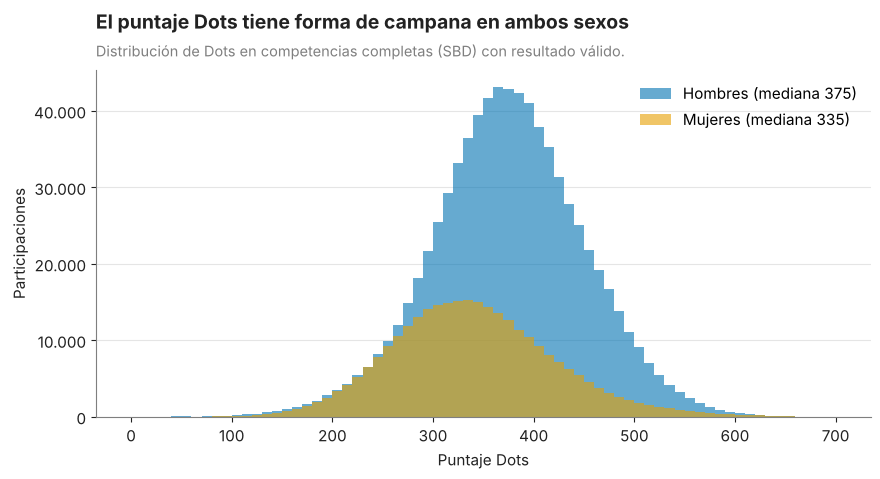

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
intervalos = np.arange(0, 701, 10)
for sexo in ['Hombres', 'Mujeres']:
    valores = df_rend.loc[df_rend['sexo'] == sexo, 'dots']
    ax.hist(valores, bins=intervalos, color=COLOR_SEXO[sexo], alpha=0.6,
            label=f'{sexo} (mediana {coma(valores.median(), 0)})')
ax.set_xlabel('Puntaje Dots')
ax.set_ylabel('Participaciones')
ax.yaxis.set_major_formatter(lambda valor, posicion: miles(valor))
ax.legend(frameon=False)
ax.grid(axis='y', color=GRID)
ax.set_axisbelow(True)
poner_titulo(ax, 'El puntaje Dots tiene forma de campana en ambos sexos',
             'Distribución de Dots en competencias completas (SBD) con resultado válido.')
guardar(fig, 'fig02_distribucion_dots.png', 'Distribución del puntaje Dots por sexo')

## 5.2 P1. ¿Cómo ha cambiado la participación de hombres y mujeres desde el año 2000?

- **Datos:** `df_limpio`, todos los eventos.
- **Periodo:** 2000 a 2025. Antes de 2000 la cobertura del dataset es irregular y 2026 está incompleto.

In [24]:
p1 = df_limpio[(df_limpio['anio'] >= 2000) & (df_limpio['anio'] <= 2025)]

tabla_p1 = p1.groupby(['anio', 'sexo']).size().unstack('sexo')
tabla_p1['Total'] = tabla_p1['Hombres'] + tabla_p1['Mujeres']
tabla_p1['% mujeres'] = (tabla_p1['Mujeres'] / tabla_p1['Total'] * 100).round(1)

f2000, f2025 = tabla_p1.loc[2000, 'Mujeres'], tabla_p1.loc[2025, 'Mujeres']
m2000, m2025 = tabla_p1.loc[2000, 'Hombres'], tabla_p1.loc[2025, 'Hombres']
caida_2020 = (tabla_p1.loc[2020, 'Total'] / tabla_p1.loc[2019, 'Total'] - 1) * 100

tabla_p1.loc[[2000, 2005, 2010, 2015, 2019, 2020, 2021, 2025]]

sexo,Hombres,Mujeres,Total,% mujeres
anio,,,,
2000,10725,2571,13296,19.3
2005,17991,4359,22350,19.5
2010,22442,5244,27686,18.9
2015,47955,18688,66643,28.0
2019,66208,31612,97820,32.3
2020,23780,10865,34645,31.4
2021,37004,17649,54653,32.3
2025,61277,30448,91725,33.2


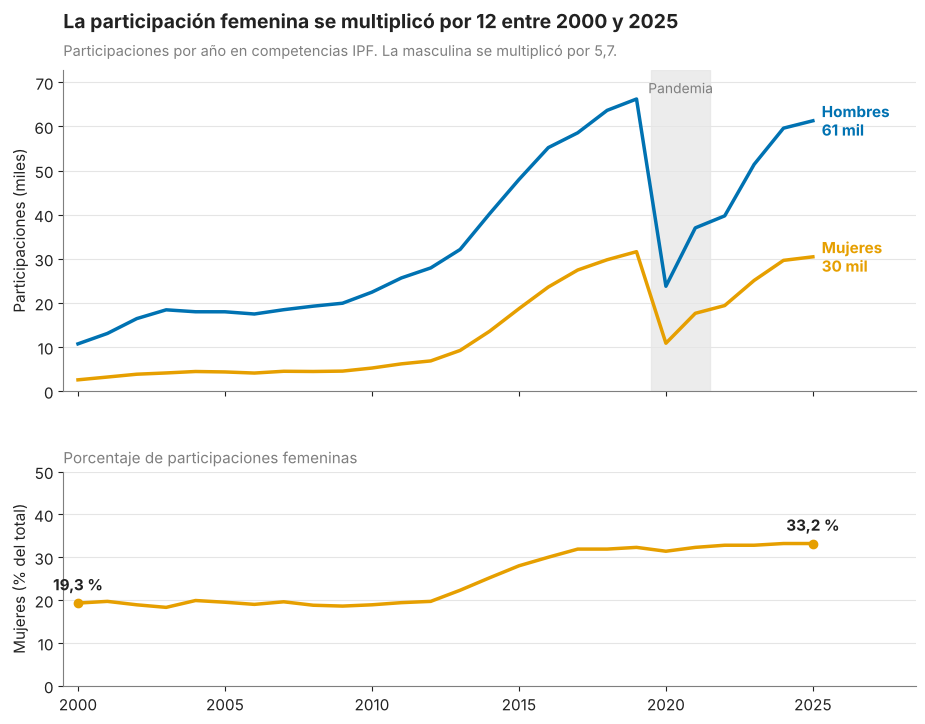

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 2], 'hspace': 0.3})

# Arriba: participaciones por sexo
for sexo in ['Hombres', 'Mujeres']:
    valores = tabla_p1[sexo] / 1000
    ax1.plot(tabla_p1.index, valores, color=COLOR_SEXO[sexo], linewidth=2.5)
    ax1.text(2025.3, valores.loc[2025], f'{sexo}\n{coma(valores.loc[2025], 0)} mil',
             color=COLOR_SEXO[sexo], va='center', fontweight='bold')

ax1.axvspan(2019.5, 2021.5, color=GRID, alpha=0.7)
ax1.text(2020.5, tabla_p1['Hombres'].max() / 1000 * 1.02, 'Pandemia', ha='center', color=GRIS, fontsize=10)
ax1.set_ylabel('Participaciones (miles)')
ax1.set_ylim(0, tabla_p1['Hombres'].max() / 1000 * 1.1)
ax1.grid(axis='y', color=GRID)
ax1.set_axisbelow(True)
poner_titulo(ax1, f'La participación femenina se multiplicó por {coma(f2025 / f2000, 0)} entre 2000 y 2025',
             f'Participaciones por año en competencias IPF. La masculina se multiplicó por {coma(m2025 / m2000, 1)}.')

# Abajo: porcentaje de mujeres
ax2.plot(tabla_p1.index, tabla_p1['% mujeres'], color=NARANJA, linewidth=2.5)
for anio in [2000, 2025]:
    ax2.scatter(anio, tabla_p1.loc[anio, '% mujeres'], color=NARANJA, zorder=3)
    ax2.text(anio, tabla_p1.loc[anio, '% mujeres'] + 3, coma(tabla_p1.loc[anio, '% mujeres']) + ' %',
             ha='center', color=TEXTO, fontweight='bold')
ax2.set_ylabel('Mujeres (% del total)')
ax2.set_ylim(0, 50)
ax2.set_xlim(1999.5, 2028.5)
ax2.set_xticks(range(2000, 2026, 5))
ax2.grid(axis='y', color=GRID)
ax2.set_axisbelow(True)
ax2.set_title('Porcentaje de participaciones femeninas', loc='left', fontsize=11, color=GRIS)

guardar(fig, 'fig03_p1_participacion.png', 'P1: participaciones por año y sexo, y porcentaje de mujeres')

**Respuesta P1**

- Las participaciones femeninas pasaron de 2.571 en el año 2000 a 30.448 en 2025: se multiplicaron por 11,8. Las masculinas pasaron de 10.725 a 61.277: se multiplicaron por 5,7.
- El porcentaje de mujeres subió de 19,3 % a 33,2 %. Se mantuvo cerca del 19 % hasta 2012, subió hasta 32 % en 2017 y desde entonces está estable.
- Ese salto coincide con los años en que la IPF empezó a organizar campeonatos Raw (2012). Los datos muestran la coincidencia, no prueban que esa sea la causa.
- En 2020 las participaciones totales cayeron 64,6 % frente a 2019 por la pandemia. En 2025 hubo 91.725, todavía por debajo del máximo de 2019 (97.820).

## 5.3 P2. ¿A qué edad se alcanza el mejor rendimiento y cuánto cae después?

- **Datos:** `df_rend`, solo equipo `Raw`, para no mezclar el efecto del equipo con el de la edad.
- **Edades:** 14 a 75 años. Fuera de ese rango hay pocos datos por edad.
- **Medida:** mediana de Dots en cada edad. La banda va del percentil 25 al 75 (la mitad central de los atletas).

Filas usadas en P2: 497.648


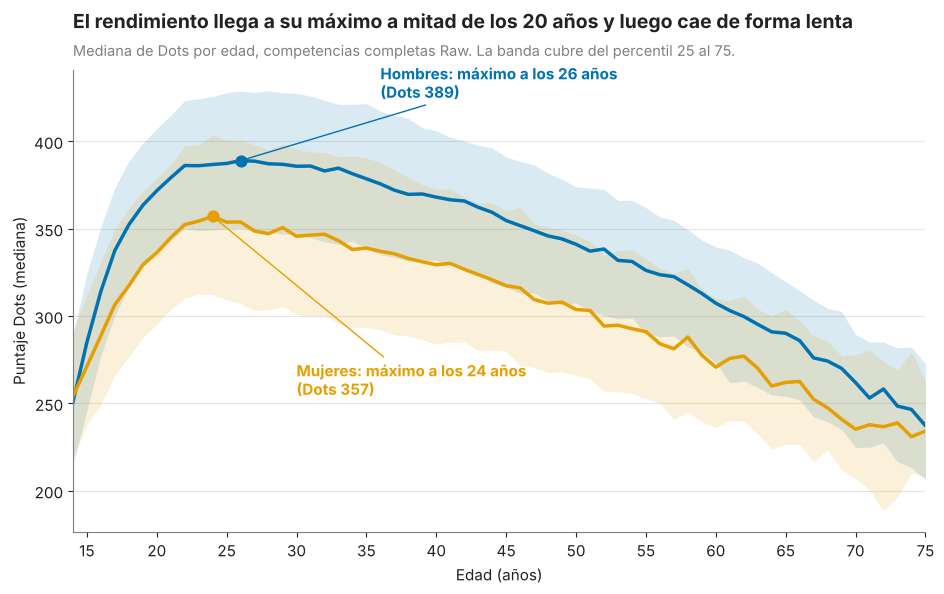

In [26]:
p2 = df_rend[(df_rend['equipo'] == 'Raw') & (df_rend['edad'] >= 14) & (df_rend['edad'] <= 75)]
print('Filas usadas en P2:', miles(len(p2)))

tabla_p2 = p2.groupby(['sexo', 'edad'])['dots'].agg(
    mediana='median',
    p25=lambda serie: serie.quantile(0.25),
    p75=lambda serie: serie.quantile(0.75),
    filas='count',
).round(1)

fig, ax = plt.subplots(figsize=(11, 6))
picos = {}
posicion_texto = {'Hombres': (36, 425), 'Mujeres': (30, 255)}   # dónde se escribe la anotación de cada sexo

for sexo in ['Hombres', 'Mujeres']:
    curva = tabla_p2.loc[sexo]
    ax.fill_between(curva.index, curva['p25'], curva['p75'], color=COLOR_SEXO[sexo], alpha=0.15, linewidth=0)
    ax.plot(curva.index, curva['mediana'], color=COLOR_SEXO[sexo], linewidth=2.5)

    # Edad con la mediana más alta
    edad_pico = curva['mediana'].idxmax()
    valor_pico = curva['mediana'].max()
    picos[sexo] = (edad_pico, valor_pico)
    ax.scatter(edad_pico, valor_pico, color=COLOR_SEXO[sexo], zorder=3, s=60)
    ax.annotate(f'{sexo}: máximo a los {edad_pico:.0f} años\n(Dots {coma(valor_pico, 0)})',
                xy=(edad_pico, valor_pico), xytext=posicion_texto[sexo],
                color=COLOR_SEXO[sexo], fontweight='bold',
                arrowprops=dict(arrowstyle='-', color=COLOR_SEXO[sexo]))

ax.set_xlabel('Edad (años)')
ax.set_ylabel('Puntaje Dots (mediana)')
ax.set_xlim(14, 75)
ax.set_xticks(range(15, 76, 5))
ax.grid(axis='y', color=GRID)
ax.set_axisbelow(True)
poner_titulo(ax, 'El rendimiento llega a su máximo a mitad de los 20 años y luego cae de forma lenta',
             'Mediana de Dots por edad, competencias completas Raw. La banda cubre del percentil 25 al 75.')
guardar(fig, 'fig04_p2_edad.png', 'P2: mediana de Dots por edad y sexo')

In [27]:
# Cifras para la respuesta
caida_60 = {}
for sexo in ['Hombres', 'Mujeres']:
    curva = tabla_p2.loc[sexo, 'mediana']
    edad_pico, valor_pico = picos[sexo]
    cerca = curva[curva >= valor_pico * 0.97]   # edades a menos del 3 % del máximo
    caida_60[sexo] = (curva.loc[60] / valor_pico - 1) * 100
    print(f'{sexo}: máximo a los {edad_pico:.0f} años (Dots {coma(valor_pico)})')
    print(f'   Edades a menos del 3 % del máximo: de {cerca.index.min():.0f} a {cerca.index.max():.0f} años')
    for edad in [18, 40, 50, 60, 70]:
        cambio = (curva.loc[edad] / valor_pico - 1) * 100
        print(f'   A los {edad} años: Dots {coma(curva.loc[edad])} ({coma(cambio)} % frente al máximo)')

Hombres: máximo a los 26 años (Dots 389,0)
   Edades a menos del 3 % del máximo: de 21 a 35 años
   A los 18 años: Dots 352,3 (-9,4 % frente al máximo)
   A los 40 años: Dots 368,1 (-5,4 % frente al máximo)
   A los 50 años: Dots 341,1 (-12,3 % frente al máximo)
   A los 60 años: Dots 307,4 (-21,0 % frente al máximo)
   A los 70 años: Dots 262,0 (-32,6 % frente al máximo)
Mujeres: máximo a los 24 años (Dots 357,1)
   Edades a menos del 3 % del máximo: de 22 a 32 años
   A los 18 años: Dots 317,4 (-11,1 % frente al máximo)
   A los 40 años: Dots 329,4 (-7,8 % frente al máximo)
   A los 50 años: Dots 303,8 (-14,9 % frente al máximo)
   A los 60 años: Dots 270,8 (-24,2 % frente al máximo)
   A los 70 años: Dots 235,3 (-34,1 % frente al máximo)


**Respuesta P2**

- La mediana de Dots más alta está a los **26 años en hombres** (389) y a los **24 años en mujeres** (357).
- El máximo es una meseta: en hombres la mediana se mantiene a menos del 3 % del máximo entre los 21 y los 35 años, y en mujeres entre los 22 y los 32.
- Después la caída es lenta y constante. Frente al máximo, a los 40 años el rendimiento es 5,4 % menor en hombres y 7,8 % menor en mujeres; a los 60, 21,0 % y 24,2 %; a los 70, 32,6 % y 34,1 %.
- La subida es más rápida que la caída: a los 18 años los atletas ya están a un 9 %–11 % del máximo.
- Las bandas se cruzan casi por completo: la diferencia entre atletas de una misma edad es mayor que la diferencia entre edades cercanas.

## 5.4 P3. ¿Cuánto peso adicional permite levantar el equipo Single-ply frente a Raw?

- **Datos:** `df_rend`, de 2012 a 2025 (la IPF organiza campeonatos Raw desde 2012) y atletas de 20 a 39 años (la etapa de mayor rendimiento según P2).
- **Medida:** peso levantado dividido entre el peso corporal («veces su peso corporal»), para que atletas livianos y pesados sean comparables.

In [28]:
p3 = df_rend[(df_rend['anio'] >= 2012) & (df_rend['anio'] <= 2025) &
             (df_rend['edad'] >= 20) & (df_rend['edad'] <= 39)].copy()

levantamientos = {'Sentadilla': 'sentadilla_kg', 'Press de banca': 'banca_kg', 'Peso muerto': 'peso_muerto_kg'}
for nombre, columna in levantamientos.items():
    p3[nombre] = p3[columna] / p3['peso_corporal_kg']

medianas = p3.groupby(['sexo', 'equipo'])[list(levantamientos)].median()

filas = []
for sexo in ['Hombres', 'Mujeres']:
    for nombre in levantamientos:
        raw = medianas.loc[(sexo, 'Raw'), nombre]
        single = medianas.loc[(sexo, 'Single-ply'), nombre]
        filas.append({'Sexo': sexo, 'Levantamiento': nombre, 'Raw': round(raw, 2), 'Single-ply': round(single, 2),
                      'Diferencia %': round((single / raw - 1) * 100, 1)})
tabla_p3 = pd.DataFrame(filas)
tabla_p3

,Sexo,Levantamiento,Raw,Single-ply,Diferencia %
0,Hombres,Sentadilla,2.33,2.79,20.0
1,Hombres,Press de banca,1.54,1.90,23.7
2,Hombres,Peso muerto,2.67,2.74,2.3
3,Mujeres,Sentadilla,1.80,2.34,30.1
4,Mujeres,Press de banca,0.99,1.32,33.2
5,Mujeres,Peso muerto,2.15,2.31,7.4


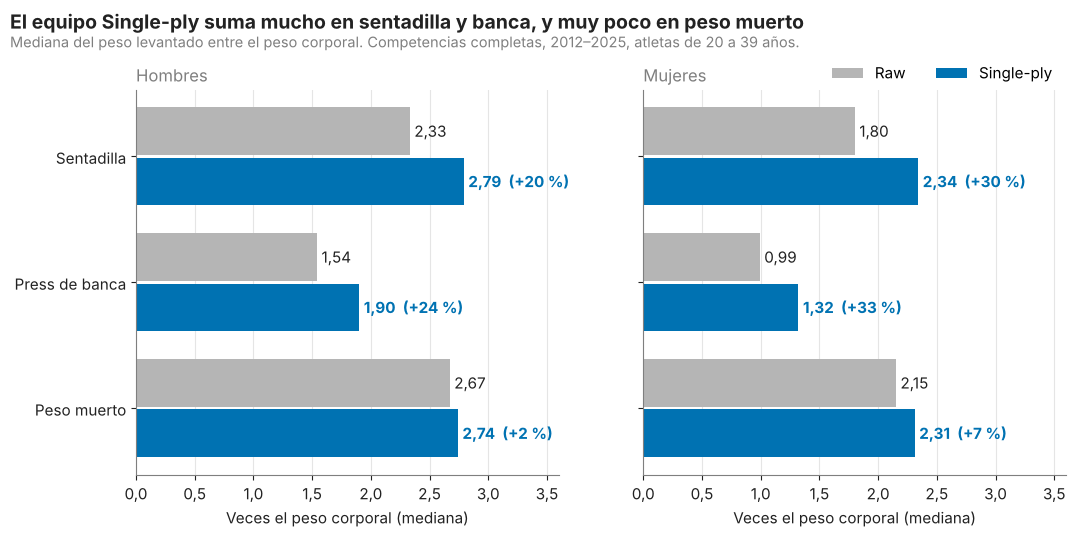

In [29]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, sexo in zip(ejes, ['Hombres', 'Mujeres']):
    datos = tabla_p3[tabla_p3['Sexo'] == sexo].iloc[::-1]   # invertido para que Sentadilla quede arriba
    y = np.arange(len(datos))
    ax.barh(y + 0.2, datos['Raw'], height=0.38, color=GRIS_CLARO, label='Raw')
    ax.barh(y - 0.2, datos['Single-ply'], height=0.38, color=AZUL, label='Single-ply')

    for posicion, (_, fila) in zip(y, datos.iterrows()):
        ax.text(fila['Raw'] + 0.04, posicion + 0.2, coma(fila['Raw'], 2), va='center', color=TEXTO)
        ax.text(fila['Single-ply'] + 0.04, posicion - 0.2,
                f"{coma(fila['Single-ply'], 2)}  (+{coma(fila['Diferencia %'], 0)} %)",
                va='center', color=AZUL, fontweight='bold')

    ax.set_yticks(y, datos['Levantamiento'])
    ax.set_xlim(0, 3.6)
    eje_con_coma(ax.xaxis)
    ax.set_xlabel('Veces el peso corporal (mediana)')
    ax.set_title(sexo, loc='left', fontsize=12, color=GRIS)
    ax.grid(axis='x', color=GRID)
    ax.set_axisbelow(True)

fig.legend(*ejes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc='upper right', bbox_to_anchor=(0.9, 0.96))
fig.suptitle('El equipo Single-ply suma mucho en sentadilla y banca, y muy poco en peso muerto',
             x=0.02, y=1.04, ha='left', fontsize=14, fontweight='bold', color=TEXTO)
fig.text(0.02, 0.965, 'Mediana del peso levantado entre el peso corporal. Competencias completas, 2012–2025, atletas de 20 a 39 años.',
         fontsize=10.5, color=GRIS)
guardar(fig, 'fig05_p3_equipo.png', 'P3: Raw frente a Single-ply en cada levantamiento')

**Respuesta P3**

- En **sentadilla**, la mediana con Single-ply es 20,0 % mayor que con Raw en hombres y 30,1 % mayor en mujeres.
- En **press de banca** está la mayor diferencia: 23,7 % en hombres y 33,2 % en mujeres.
- En **peso muerto** la diferencia es pequeña: 2,3 % en hombres y 7,4 % en mujeres.
- La diferencia relativa es mayor en mujeres en los tres levantamientos.
- El resultado es consistente con el diseño del equipo: el traje y la camisa dan soporte sobre todo en la sentadilla y en la banca.

## 5.5 Relación entre el peso corporal y el total

Antes de modelar se revisa cómo se relaciona el total con el peso corporal, que es la variable numérica más ligada a la fuerza. Con cientos de miles de puntos un diagrama de dispersión se vuelve una mancha, así que se usan hexágonos: cada uno es más oscuro cuantas más participaciones contiene.

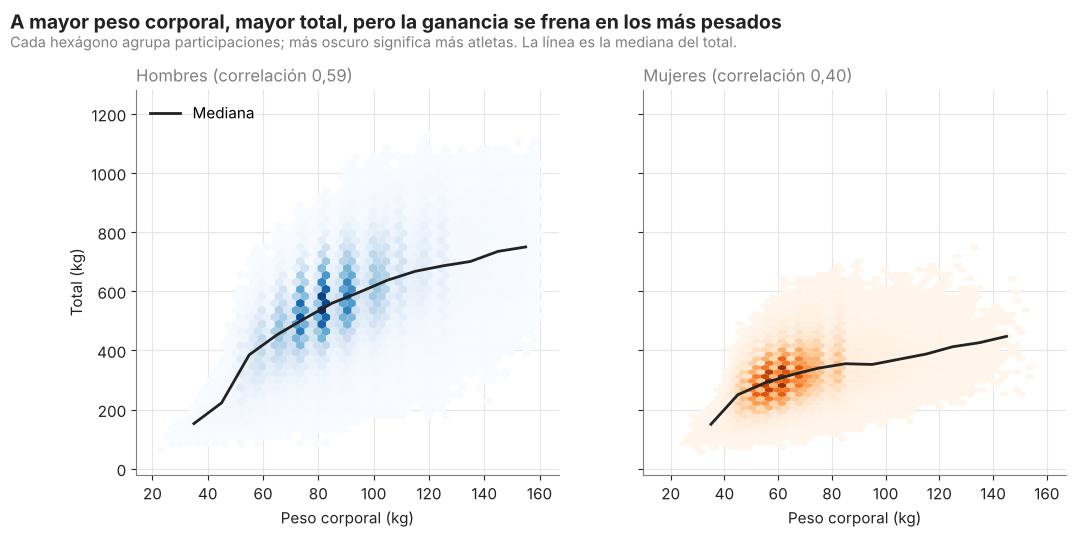

In [30]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
mapas = {'Hombres': 'Blues', 'Mujeres': 'Oranges'}

for ax, sexo in zip(ejes, ['Hombres', 'Mujeres']):
    datos = df_rend[(df_rend['sexo'] == sexo) & (df_rend['peso_corporal_kg'] <= 160)]
    ax.hexbin(datos['peso_corporal_kg'], datos['total_kg'], gridsize=45, cmap=mapas[sexo], mincnt=5, linewidths=0)

    # Mediana del total en tramos de 10 kg de peso corporal
    tramos = (datos['peso_corporal_kg'] // 10 * 10 + 5)
    mediana_tramo = datos.groupby(tramos)['total_kg'].median()
    mediana_tramo = mediana_tramo[datos.groupby(tramos).size() >= 200]
    ax.plot(mediana_tramo.index, mediana_tramo.values, color=TEXTO, linewidth=2, label='Mediana')

    correlacion = datos['peso_corporal_kg'].corr(datos['total_kg'])
    ax.set_title(f'{sexo} (correlación {coma(correlacion, 2)})', loc='left', fontsize=12, color=GRIS)
    ax.set_xlabel('Peso corporal (kg)')
    ax.grid(color=GRID)
    ax.set_axisbelow(True)

ejes[0].set_ylabel('Total (kg)')
ejes[0].legend(frameon=False, loc='upper left')
fig.suptitle('A mayor peso corporal, mayor total, pero la ganancia se frena en los más pesados',
             x=0.02, y=1.04, ha='left', fontsize=14, fontweight='bold', color=TEXTO)
fig.text(0.02, 0.965, 'Cada hexágono agrupa participaciones; más oscuro significa más atletas. La línea es la mediana del total.',
         fontsize=10.5, color=GRIS)
guardar(fig, 'fig06_peso_vs_total.png', 'Relación entre peso corporal y total, por sexo')

La relación es positiva pero curva, y es distinta en cada sexo. Un modelo lineal simple no la captura del todo; por eso en el modelado se compara una regresión lineal con dos modelos de árboles.

---
# 6. Modeling

## 6.1 Datos del modelo

- **Variable objetivo:** `total_kg`.
- **Variables de entrada (7):** `sexo`, `equipo`, `edad`, `peso_corporal_kg`, `anio`, `competencias_previas`, `anios_experiencia`.
- **Filas:** `df_rend` con edad conocida entre 10 y 85 años.

### Cómo se evitó la fuga de información (data leakage)

1. **No entran columnas calculadas con el resultado.** Sentadilla, banca, peso muerto, Dots, fuerza relativa y puesto se conocen después de competir, y el total es su suma. Usarlas sería darle la respuesta al modelo.
2. **La experiencia solo mira hacia atrás.** `competencias_previas` y `anios_experiencia` se calcularon con las competencias anteriores a cada fecha.
3. **Un atleta no está a la vez en entrenamiento y en prueba.** Muchos atletas tienen varias filas. Con una división al azar, el modelo vería en entrenamiento a los mismos atletas de la prueba. Se divide por atleta (`GroupShuffleSplit`).
4. **El escalado y la codificación se ajustan solo con entrenamiento.** Van dentro de un `Pipeline` de scikit-learn, que los ajusta con los datos de entrenamiento y los aplica a los de prueba.

In [31]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

SEMILLA = 42
variables_numericas   = ['edad', 'peso_corporal_kg', 'anio', 'competencias_previas', 'anios_experiencia']
variables_categoricas = ['sexo', 'equipo']
variables = variables_numericas + variables_categoricas

datos_modelo = df_rend[df_rend['edad'].between(10, 85)]
X = datos_modelo[variables]
y = datos_modelo['total_kg']
grupos = datos_modelo['nombre'].astype(str)

# División 80 % entrenamiento / 20 % prueba, por atleta
divisor = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA)
indices_train, indices_test = next(divisor.split(X, y, grupos))
X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]

atletas_en_ambos = set(grupos.iloc[indices_train]) & set(grupos.iloc[indices_test])
print('Filas del modelo:', miles(len(datos_modelo)))
print('Entrenamiento:', miles(len(X_train)), 'filas |', 'Prueba:', miles(len(X_test)), 'filas')
print('Atletas que están en ambos conjuntos:', len(atletas_en_ambos))

Filas del modelo: 791.770
Entrenamiento: 632.815 filas | Prueba: 158.955 filas
Atletas que están en ambos conjuntos: 0


## 6.2 Modelos

| Modelo | Descripción | Preparación de variables |
|---|---|---|
| **Línea base** | Predice siempre el promedio del total de entrenamiento | Ninguna |
| **Regresión lineal** | Suma ponderada de las variables | Numéricas escaladas (`StandardScaler`), categóricas en columnas 0/1 (`OneHotEncoder`) |
| **Random Forest** (`RandomForestRegressor`) | Muchos árboles de decisión independientes, cada uno entrenado con una muestra distinta de los datos; la predicción es el promedio de todos | Igual que Gradient Boosting. Cada árbol usa una muestra de 150.000 filas para que el entrenamiento sea rápido |
| **Gradient Boosting** (`HistGradientBoostingRegressor`) | Muchos árboles de decisión pequeños; cada uno corrige el error de los anteriores | Categóricas convertidas a número (`OrdinalEncoder`) y marcadas como categóricas. No necesita escalado |

In [32]:
preparacion_lineal = ColumnTransformer([
    ('numericas', StandardScaler(), variables_numericas),
    ('categoricas', OneHotEncoder(handle_unknown='ignore'), variables_categoricas),
])

preparacion_arboles = ColumnTransformer([
    ('numericas', 'passthrough', variables_numericas),
    ('categoricas', OrdinalEncoder(), variables_categoricas),
])
posiciones_categoricas = [len(variables_numericas), len(variables_numericas) + 1]

modelos = {
    'Línea base (promedio)': DummyRegressor(strategy='mean'),
    'Regresión lineal': Pipeline([('preparacion', preparacion_lineal),
                                  ('modelo', LinearRegression())]),
    'Random Forest': Pipeline([('preparacion', preparacion_arboles),
                               ('modelo', RandomForestRegressor(n_estimators=50, max_depth=14, min_samples_leaf=20,
                                                                max_samples=150_000, n_jobs=-1, random_state=SEMILLA))]),
    'Gradient Boosting': Pipeline([('preparacion', preparacion_arboles),
                                   ('modelo', HistGradientBoostingRegressor(categorical_features=posiciones_categoricas,
                                                                            random_state=SEMILLA))]),
}

resultados = []
predicciones = {}
for nombre, modelo in modelos.items():
    inicio = time.time()
    modelo.fit(X_train, y_train)
    segundos = time.time() - inicio
    predicciones[nombre] = modelo.predict(X_test)
    resultados.append({
        'modelo': nombre,
        'MAE': round(mean_absolute_error(y_test, predicciones[nombre]), 1),
        'RMSE': round(root_mean_squared_error(y_test, predicciones[nombre]), 1),
        'R2': round(r2_score(y_test, predicciones[nombre]), 3) + 0.0,   # + 0.0 evita que se muestre -0.0
        'segundos_entrenamiento': round(segundos, 1),
    })

tabla_modelos = pd.DataFrame(resultados)
mae_base = tabla_modelos.loc[0, 'MAE']
tabla_modelos['mejora_MAE_%'] = ((1 - tabla_modelos['MAE'] / mae_base) * 100).round(1)
tabla_modelos

,modelo,MAE,RMSE,R2,segundos_entrenamiento,mejora_MAE_%
0,Línea base (promedio),140.0,169.6,0.000,0.0,0.0
1,Regresión lineal,77.1,99.9,0.653,0.7,44.9
2,Random Forest,57.5,75.8,0.800,11.1,58.9
3,Gradient Boosting,57.2,75.4,0.803,3.0,59.1


---
# 7. Evaluation

## 7.1 Métricas

- **MAE** (error absoluto medio): en promedio, cuántos kilos se equivoca el modelo. Es la métrica principal porque se lee directamente en kilos.
- **RMSE:** parecido al MAE, pero castiga más los errores grandes.
- **R²:** qué parte de la variación del total explica el modelo (0 = nada, 1 = todo).

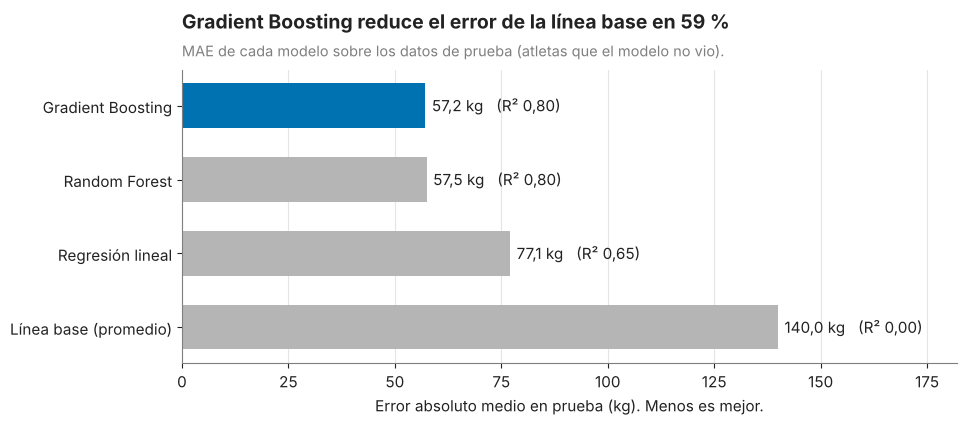

In [33]:
mejor = tabla_modelos.sort_values('MAE').iloc[0]
NOMBRE_MEJOR = mejor['modelo']
mejor_modelo = modelos[NOMBRE_MEJOR]

fig, ax = plt.subplots(figsize=(10, 3.8))
orden = tabla_modelos.sort_values('MAE', ascending=False)
colores = [AZUL if nombre == NOMBRE_MEJOR else GRIS_CLARO for nombre in orden['modelo']]
ax.barh(orden['modelo'], orden['MAE'], color=colores, height=0.6)
for y_pos, (_, fila) in enumerate(orden.iterrows()):
    ax.text(fila['MAE'] + 1.5, y_pos, f"{coma(fila['MAE'])} kg   (R² {coma(fila['R2'], 2)})", va='center', color=TEXTO)
ax.set_xlim(0, mae_base * 1.3)
ax.set_xlabel('Error absoluto medio en prueba (kg). Menos es mejor.')
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
poner_titulo(ax, f"{NOMBRE_MEJOR} reduce el error de la línea base en {coma(mejor['mejora_MAE_%'], 0)} %",
             'MAE de cada modelo sobre los datos de prueba (atletas que el modelo no vio).')
guardar(fig, 'fig07_comparacion_modelos.png', 'Comparación del MAE de los modelos')

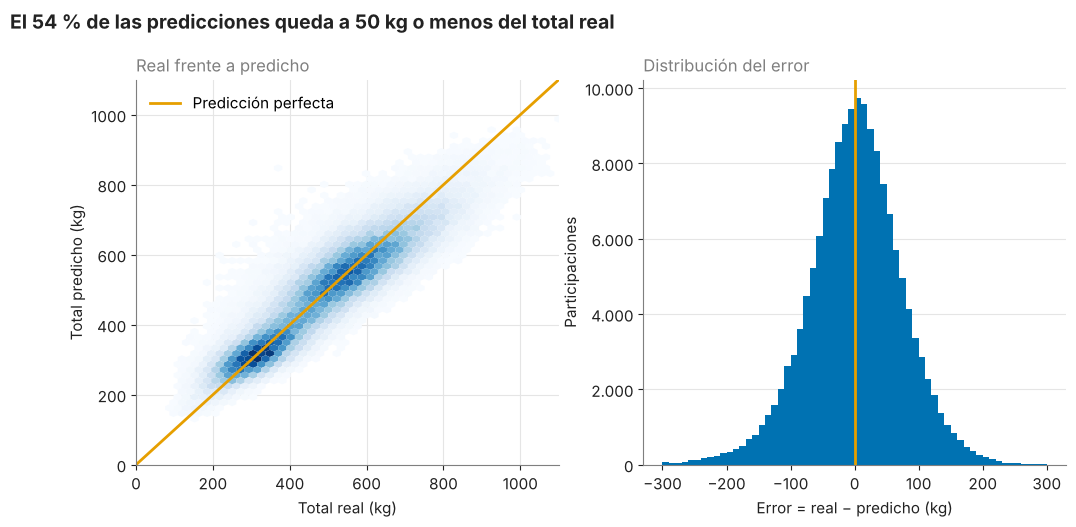

Error mediano: 45,4 kg
Predicciones a 50 kg o menos del real: 54,1 %


In [34]:
# Valor real frente a valor predicho (mejor modelo)
prediccion_mejor = predicciones[NOMBRE_MEJOR]
errores = y_test.values - prediccion_mejor

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.hexbin(y_test, prediccion_mejor, gridsize=50, cmap='Blues', mincnt=5, linewidths=0)
limite = [0, 1100]
ax1.plot(limite, limite, color=NARANJA, linewidth=2, label='Predicción perfecta')
ax1.set_xlim(limite); ax1.set_ylim(limite)
ax1.set_xlabel('Total real (kg)')
ax1.set_ylabel('Total predicho (kg)')
ax1.legend(frameon=False, loc='upper left')
ax1.grid(color=GRID); ax1.set_axisbelow(True)
ax1.set_title('Real frente a predicho', loc='left', fontsize=12, color=GRIS)

ax2.hist(errores, bins=np.arange(-300, 301, 10), color=AZUL)
ax2.axvline(0, color=NARANJA, linewidth=2)
ax2.set_xlabel('Error = real − predicho (kg)')
ax2.set_ylabel('Participaciones')
ax2.yaxis.set_major_formatter(lambda valor, posicion: miles(valor))
ax2.grid(axis='y', color=GRID); ax2.set_axisbelow(True)
ax2.set_title('Distribución del error', loc='left', fontsize=12, color=GRIS)

dentro_50 = (np.abs(errores) <= 50).mean() * 100
fig.suptitle(f'El {coma(dentro_50, 0)} % de las predicciones queda a 50 kg o menos del total real',
             x=0.02, y=1.02, ha='left', fontsize=14, fontweight='bold', color=TEXTO)
guardar(fig, 'fig08_real_vs_predicho.png', 'Total real frente a predicho y distribución del error')

print('Error mediano:', coma(np.median(np.abs(errores))), 'kg')
print('Predicciones a 50 kg o menos del real:', coma(dentro_50), '%')

## 7.2 Interpretación: qué variables pesan más

Se usa **importancia por permutación**: se desordena una variable en los datos de prueba y se mide cuánto empeora el MAE. Si el error sube mucho, el modelo depende de esa variable. Se calcula sobre una muestra de 30.000 filas de prueba.

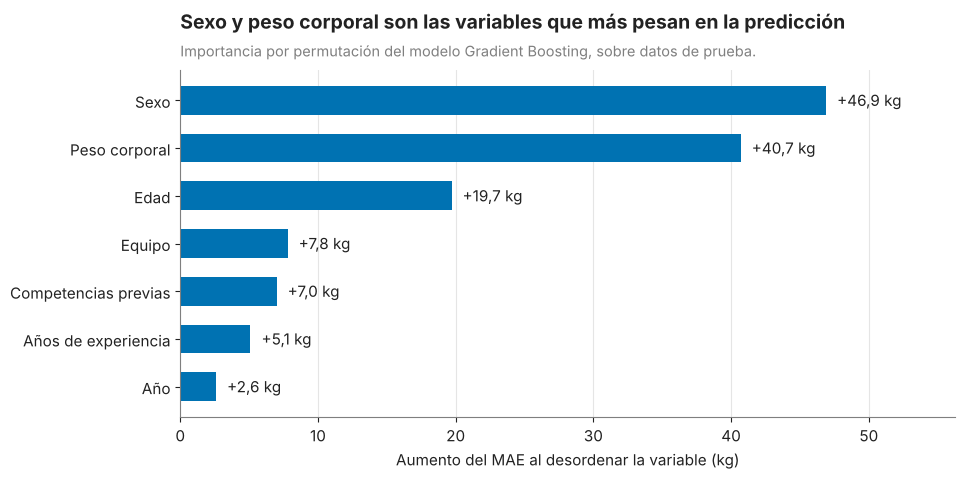

,variable,aumento_MAE_kg
5,Sexo,46.9
1,Peso corporal,40.7
0,Edad,19.7
6,Equipo,7.8
3,Competencias previas,7.0
4,Años de experiencia,5.1
2,Año,2.6


In [35]:
muestra_test = X_test.sample(30_000, random_state=SEMILLA)
importancia = permutation_importance(mejor_modelo, muestra_test, y_test.loc[muestra_test.index],
                                     scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMILLA)

nombres_legibles = {'sexo': 'Sexo', 'equipo': 'Equipo', 'edad': 'Edad', 'peso_corporal_kg': 'Peso corporal',
                    'anio': 'Año', 'competencias_previas': 'Competencias previas', 'anios_experiencia': 'Años de experiencia'}
tabla_importancia = (pd.DataFrame({'variable': [nombres_legibles[v] for v in variables],
                                   'aumento_MAE_kg': importancia.importances_mean.round(1)})
                     .sort_values('aumento_MAE_kg'))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(tabla_importancia['variable'], tabla_importancia['aumento_MAE_kg'], color=AZUL, height=0.6)
for y_pos, valor in enumerate(tabla_importancia['aumento_MAE_kg']):
    ax.text(valor + 0.8, y_pos, '+' + coma(valor) + ' kg', va='center', color=TEXTO)
ax.set_xlim(0, tabla_importancia['aumento_MAE_kg'].max() * 1.2)
ax.set_xlabel('Aumento del MAE al desordenar la variable (kg)')
ax.grid(axis='x', color=GRID)
ax.set_axisbelow(True)
principal = tabla_importancia.iloc[-1]['variable']
segunda = tabla_importancia.iloc[-2]['variable']
poner_titulo(ax, f'{principal} y {segunda.lower()} son las variables que más pesan en la predicción',
             f'Importancia por permutación del modelo {NOMBRE_MEJOR}, sobre datos de prueba.')
guardar(fig, 'fig09_importancia_variables.png', 'Importancia de las variables del modelo')

tabla_importancia.sort_values('aumento_MAE_kg', ascending=False)

In [36]:
# Error del mejor modelo por sexo y equipo: ¿se equivoca más en algún grupo?
evaluacion = X_test[['sexo', 'equipo']].copy()
evaluacion['error_absoluto'] = np.abs(errores)
evaluacion['total_real'] = y_test.values
error_por_grupo = (evaluacion.groupby(['sexo', 'equipo'])
                   .agg(filas=('error_absoluto', 'size'), MAE_kg=('error_absoluto', 'mean'),
                        total_promedio_kg=('total_real', 'mean')).round(1))
error_por_grupo['MAE_%_del_total'] = (error_por_grupo['MAE_kg'] / error_por_grupo['total_promedio_kg'] * 100).round(1)
error_por_grupo

filas  MAE_kg  total_promedio_kg  MAE_%_del_total
sexo    equipo                                                       
Hombres Raw         67653    59.0              541.5             10.9
        Single-ply  42997    70.1              603.2             11.6
Mujeres Raw         33849    40.0              315.6             12.7
        Single-ply  14456    50.6              349.3             14.5

In [37]:
# Criterio de éxito definido en la sección 1.4
cumple_mae = mejor['mejora_MAE_%'] >= 40
cumple_r2 = mejor['R2'] >= 0.70
print(f"Mejora del MAE frente a la línea base: {coma(mejor['mejora_MAE_%'])} % (meta: 40 %) ->", 'CUMPLE' if cumple_mae else 'NO CUMPLE')
print(f"R² en prueba: {coma(mejor['R2'], 3)} (meta: 0,70) ->", 'CUMPLE' if cumple_r2 else 'NO CUMPLE')

Mejora del MAE frente a la línea base: 59,1 % (meta: 40 %) -> CUMPLE
R² en prueba: 0,803 (meta: 0,70) -> CUMPLE


## 7.4 Rango de fuerza: modelos de cuantiles

El modelo anterior da un solo número: el total de un atleta típico. Dos atletas con el mismo sexo, peso y edad pueden levantar totales muy distintos, así que para el predictor del dashboard hace falta un **rango**.

Se entrenan tres modelos Gradient Boosting con pérdida de cuantil, con las mismas variables y los mismos datos de entrenamiento:

- **P10:** total que supera el 90 % de los atletas con ese perfil (límite bajo).
- **P50:** total del atleta típico (mediana).
- **P90:** total que solo supera el 10 % de los atletas con ese perfil (límite alto).

Se evalúan con la **cobertura** en prueba: si el rango está bien calibrado, cerca del 80 % de los totales reales debe quedar entre P10 y P90.

In [38]:
modelos_cuantiles = {}
for cuantil in [10, 50, 90]:
    modelo_q = Pipeline([('preparacion', preparacion_arboles),
                         ('modelo', HistGradientBoostingRegressor(loss='quantile', quantile=cuantil / 100,
                                                                  categorical_features=posiciones_categoricas,
                                                                  random_state=SEMILLA))])
    modelos_cuantiles[cuantil] = modelo_q.fit(X_train, y_train)

p10, p50, p90 = [modelos_cuantiles[c].predict(X_test) for c in [10, 50, 90]]
cobertura = float(((y_test >= p10) & (y_test <= p90)).mean() * 100)
bajo_p10 = float((y_test < p10).mean() * 100)
sobre_p90 = float((y_test > p90).mean() * 100)
ancho_rango = float(np.median(p90 - p10))
mae_p50 = float(mean_absolute_error(y_test, p50))

print(f'Totales reales dentro del rango P10–P90: {coma(cobertura)} % (esperado: 80 %)')
print(f'Por debajo de P10: {coma(bajo_p10)} % (esperado: 10 %) | Por encima de P90: {coma(sobre_p90)} % (esperado: 10 %)')
print(f'Ancho típico del rango: {coma(ancho_rango, 0)} kg')
print(f'MAE del modelo P50: {coma(mae_p50)} kg')

Totales reales dentro del rango P10–P90: 79,6 % (esperado: 80 %)
Por debajo de P10: 10,2 % (esperado: 10 %) | Por encima de P90: 10,1 % (esperado: 10 %)
Ancho típico del rango: 179 kg
MAE del modelo P50: 57,2 kg


El rango queda bien calibrado si la cobertura está cerca de 80 %. Su ancho muestra cuánto varía el total entre atletas del mismo perfil: es la parte que las siete variables no explican.

In [39]:
# Se guardan el mejor modelo y los modelos de cuantiles para que el dashboard los use sin reentrenar
joblib.dump({'modelo': mejor_modelo, 'variables': variables, 'nombre': NOMBRE_MEJOR,
             'mae': float(mejor['MAE']), 'cuantiles': modelos_cuantiles}, DIR_MODELS / 'modelo.joblib', compress=3)
print('Modelo guardado en models/modelo.joblib')

Modelo guardado en models/modelo.joblib


**Respuesta P4**

- **Error:** el mejor modelo (Gradient Boosting) se equivoca en promedio 57,2 kg al estimar el total, con un R² de 0,80. La línea base se equivoca 140,0 kg y la regresión lineal 77,1 kg.
- **Criterio de éxito:** se cumple. El MAE baja 59,1 % frente a la línea base (la meta era 40 %) y el R² supera 0,70.
- **Por qué gana a la regresión lineal:** la relación entre el peso corporal, la edad y el total es curva y distinta en cada sexo (secciones 5.3 y 5.5). Los árboles capturan esas curvas y combinaciones; la regresión lineal solo puede sumar efectos rectos.
- **Variables que más pesan:** sexo y peso corporal, seguidas de la edad. El equipo y la experiencia aportan menos, y el año casi nada.
- **Lectura de negocio:** con siete datos que se conocen al inscribir a un atleta, el modelo explica el 80 % de las diferencias de total entre atletas. El 20 % restante depende de cosas que el dataset no tiene: entrenamiento, genética, técnica e historial de marcas.
- **Dónde falla más:** en kilos, el error es mayor en hombres con Single-ply (70 kg), que son quienes más levantan. En proporción al total, el error está entre 11 % y 15 % en todos los grupos y es algo mayor en mujeres.
- **Uso adecuado:** sirve como referencia de lo que levanta un atleta típico con esas características. No sirve para predecir la marca exacta de una persona: solo el 54 % de las predicciones queda a 50 kg o menos del valor real.

## 7.3 Limitaciones

- **Cada fila es una participación, no una persona.** En P1 se mide actividad competitiva, no número de atletas.
- **Cobertura.** El dataset depende de qué federaciones tienen sus resultados digitalizados. Parte del crecimiento de P1 puede venir de un mejor registro reciente.
- **Edad.** Falta en cerca de una cuarta parte de las filas, que no entran en P2 ni en el modelo. P2 compara atletas distintos en cada edad, no sigue a los mismos atletas. Quienes compiten a los 60 o 70 años son un grupo seleccionado.
- **Equipo.** Los atletas no se asignaron al azar a Raw o Single-ply. La diferencia de P3 mezcla el efecto del equipo con el nivel del atleta.
- **Nombres repetidos.** La experiencia se calcula por nombre. Dos personas con el mismo nombre se cuentan como una.
- **Modelo.** No conoce el historial de marcas del atleta, su estatura ni su entrenamiento. Sirve para ubicar a un atleta frente a sus pares, no para predecir una marca individual con precisión.
- **Solo IPF.** Los resultados no se generalizan a federaciones sin control antidopaje.

---
# 8. Deployment

## 8.1 Documento de análisis en MongoDB

Se guarda un solo documento con la metadata, la calidad de los datos, las estadísticas, las agregaciones, el modelo, los insights y las recomendaciones. El dashboard y el reporte PDF leen de ahí.

Los datos de conexión vienen de variables de entorno (archivo `.env`). Dentro de Docker el servidor se llama `mongo`.

In [40]:
from pymongo import MongoClient

MONGO_HOST = os.environ.get('MONGO_HOST', 'localhost')
MONGO_PORT = int(os.environ.get('MONGO_PORT', 27017))
MONGO_USER = os.environ.get('MONGO_USER', '')
MONGO_PASSWORD = os.environ.get('MONGO_PASSWORD', '')
MONGO_DB = os.environ.get('MONGO_DB', 'powerlifting')

if MONGO_USER:
    cliente = MongoClient(host=MONGO_HOST, port=MONGO_PORT, username=MONGO_USER, password=MONGO_PASSWORD,
                          serverSelectionTimeoutMS=10000)
else:
    cliente = MongoClient(host=MONGO_HOST, port=MONGO_PORT, serverSelectionTimeoutMS=10000)

cliente.admin.command('ping')   # falla si MongoDB no responde
coleccion = cliente[MONGO_DB]['analisis']
print(f'Conectado a MongoDB en {MONGO_HOST}:{MONGO_PORT}, base de datos "{MONGO_DB}"')

Conectado a MongoDB en localhost:27017, base de datos "powerlifting"


In [41]:
from datetime import datetime

hombres_p3 = tabla_p3[tabla_p3['Sexo'] == 'Hombres'].set_index('Levantamiento')['Diferencia %']
mujeres_p3 = tabla_p3[tabla_p3['Sexo'] == 'Mujeres'].set_index('Levantamiento')['Diferencia %']
importancia_ordenada = tabla_importancia.sort_values('aumento_MAE_kg', ascending=False)

# Los insights se arman con las cifras calculadas arriba
insights = [
    {'tema': 'participacion',
     'titulo': 'La participación femenina creció el doble de rápido que la masculina',
     'texto': f'Entre 2000 y 2025 las participaciones de mujeres pasaron de {miles(f2000)} a {miles(f2025)} '
              f'(se multiplicaron por {coma(f2025 / f2000)}); las de hombres se multiplicaron por {coma(m2025 / m2000)}. '
              f"Las mujeres pasaron del {coma(tabla_p1.loc[2000, '% mujeres'])} % al {coma(tabla_p1.loc[2025, '% mujeres'])} % del total."},
    {'tema': 'participacion',
     'titulo': 'La pandemia redujo la actividad en casi dos tercios',
     'texto': f"En 2020 las participaciones cayeron {coma(abs(caida_2020))} % frente a 2019 "
              f"(de {miles(tabla_p1.loc[2019, 'Total'])} a {miles(tabla_p1.loc[2020, 'Total'])}). "
              f"En 2025 hubo {miles(tabla_p1.loc[2025, 'Total'])}."},
    {'tema': 'edad',
     'titulo': 'El mejor rendimiento se alcanza a mitad de los 20 años',
     'texto': f"La mediana de Dots más alta está a los {picos['Hombres'][0]:.0f} años en hombres y a los "
              f"{picos['Mujeres'][0]:.0f} en mujeres. A los 60 años el rendimiento es "
              f"{coma(abs(caida_60['Hombres']))} % menor en hombres y {coma(abs(caida_60['Mujeres']))} % menor en mujeres."},
    {'tema': 'equipo',
     'titulo': 'El equipo Single-ply ayuda en sentadilla y banca, casi nada en peso muerto',
     'texto': f"Frente a Raw, la mediana con Single-ply es {coma(hombres_p3['Sentadilla'])} % mayor en sentadilla, "
              f"{coma(hombres_p3['Press de banca'])} % en press de banca y {coma(hombres_p3['Peso muerto'])} % en peso muerto (hombres). "
              f"En mujeres: {coma(mujeres_p3['Sentadilla'])} %, {coma(mujeres_p3['Press de banca'])} % y {coma(mujeres_p3['Peso muerto'])} %."},
    {'tema': 'modelo',
     'titulo': 'El total se puede estimar con datos conocidos antes de competir',
     'texto': f"El modelo {NOMBRE_MEJOR} tiene un MAE de {coma(mejor['MAE'])} kg y un R² de {coma(mejor['R2'], 2)} en datos de prueba. "
              f"Reduce el error de la línea base ({coma(mae_base)} kg) en {coma(mejor['mejora_MAE_%'])} %."},
    {'tema': 'modelo',
     'titulo': 'Las variables que más pesan en la predicción',
     'texto': f"Las más importantes son {importancia_ordenada.iloc[0]['variable'].lower()}, "
              f"{importancia_ordenada.iloc[1]['variable'].lower()} y {importancia_ordenada.iloc[2]['variable'].lower()}. "
              f"Al desordenar la primera, el MAE sube {coma(importancia_ordenada.iloc[0]['aumento_MAE_kg'])} kg."},
    {'tema': 'calidad',
     'titulo': 'Una cuarta parte de las filas no tiene edad',
     'texto': f"La edad falta en el {coma(nulos['Age'])} % de las filas del archivo original. "
              'Es la principal limitación para los análisis por edad y para el modelo.'},
]

recomendaciones = [
    {'dirigida_a': 'Federaciones',
     'texto': 'Registrar siempre la fecha de nacimiento del atleta. Es el dato faltante que más limita el análisis.'},
    {'dirigida_a': 'Federaciones',
     'texto': 'Mantener la oferta de competencias Raw: el aumento de la participación femenina coincide con su introducción en 2012.'},
    {'dirigida_a': 'Entrenadores',
     'texto': 'Usar el modelo como referencia de lo que levanta un atleta típico con el mismo sexo, peso, edad y experiencia, '
              'no como predicción exacta: el error típico es de varias decenas de kilos.'},
    {'dirigida_a': 'Organizadores',
     'texto': 'No comparar marcas Raw y Single-ply en una misma clasificación: la diferencia supera el 20 % en sentadilla y banca.'},
    {'dirigida_a': 'Equipo de datos',
     'texto': 'Agregar al modelo el mejor total anterior del atleta. Es la información que más reduciría el error.'},
]

documento = {
    '_id': 'analisis_powerlifting',
    'metadata': {
        'fecha_analisis': datetime.now().strftime('%Y-%m-%d %H:%M'),
        'autores': ['Oscar Alejandro Morales Calderón'],
        'dataset': {
            'nombre': 'OpenIPF (OpenPowerlifting)',
            'fuente': 'Proyecto OpenPowerlifting',
            'url': 'https://openpowerlifting.gitlab.io/opl-csv/bulk-csv.html',
            'archivo': os.path.basename(RUTA_CSV),
            'registros': filas_crudo,
            'columnas': columnas_crudo,
            'peso_disco_mb': round(peso_disco_mb, 1),
            'memoria_mb': round(memoria_mb, 1),
            'fecha_minima': str(fecha_min),
            'fecha_maxima': str(fecha_max),
        },
        'herramienta_procesamiento': 'pandas',
    },
    'calidad_datos': {
        'problemas_detectados': [
            {'problema': 'Filas duplicadas exactas', 'cantidad': duplicados, 'solucion': 'Se eliminaron'},
            {'problema': 'Edades fuera de 8 a 90 años', 'cantidad': edades_imposibles, 'solucion': 'Se dejaron como dato faltante'},
            {'problema': 'Edades aproximadas terminadas en ,5', 'cantidad': edades_medio_anio, 'solucion': 'Se tomó la parte entera'},
            {'problema': 'Filas con un mejor levantamiento negativo', 'cantidad': mejores_negativos, 'solucion': 'Se dejaron como dato faltante'},
            {'problema': 'Filas sin resultado válido (DQ, NS, DD)', 'cantidad': sin_resultado, 'solucion': 'Se marcaron y no entran al análisis de rendimiento'},
            {'problema': 'Edad nula (% de filas)', 'cantidad': round(float(nulos['Age']), 1), 'solucion': 'Esas filas no entran en P2 ni en el modelo'},
        ],
        'registros_eliminados': filas_crudo - filas_limpio,
        'registros_limpios': filas_limpio,
        'registros_rendimiento': len(df_rend),
        'pasos_etl': registro_etl,
    },
    'estadisticas_descriptivas': estadisticas_limpio.to_dict(),
    'agregaciones': [
        {'nombre': 'Participaciones por año y sexo (2000-2025)',
         'datos': tabla_p1.reset_index().astype({'anio': str}).to_dict('records')},
        {'nombre': 'Raw frente a Single-ply (veces el peso corporal, mediana)',
         'datos': tabla_p3.to_dict('records')},
        {'nombre': 'Mediana de Dots por grupo de edad y sexo (Raw)',
         'datos': (df_rend[(df_rend['equipo'] == 'Raw') & (df_rend['grupo_edad'] != 'Sin dato')]
                   .pivot_table(index='grupo_edad', columns='sexo', values='dots', aggfunc='median')
                   .reindex(orden_edad).round(1).reset_index().to_dict('records'))},
    ],
    'modelo': {
        'tarea': 'Regresión',
        'objetivo': 'total_kg',
        'algoritmo': NOMBRE_MEJOR,
        'variables': variables,
        'filas_entrenamiento': len(X_train),
        'filas_prueba': len(X_test),
        'metricas': {'MAE': mejor['MAE'], 'RMSE': mejor['RMSE'], 'R2': mejor['R2'], 'mejora_MAE_%': mejor['mejora_MAE_%']},
        'linea_base': tabla_modelos.iloc[0][['MAE', 'RMSE', 'R2']].to_dict(),
        'comparacion': tabla_modelos.to_dict('records'),
        'variables_importantes': importancia_ordenada.to_dict('records'),
        'criterio_exito': {'mejora_MAE_minima_%': 40, 'R2_minimo': 0.70, 'cumple': bool(cumple_mae and cumple_r2)},
        'rango_cuantiles': {'cuantiles': [10, 50, 90], 'cobertura_P10_P90_%': round(cobertura, 1),
                            'ancho_tipico_kg': round(ancho_rango), 'MAE_P50': round(mae_p50, 1)},
    },
    'insights': insights,
    'visualizaciones_generadas': figuras_generadas,
    'recomendaciones': recomendaciones,
}

# MongoDB no acepta tipos de numpy: se pasa todo a tipos básicos de Python con JSON
documento = json.loads(json.dumps(documento, default=lambda valor: valor.item() if hasattr(valor, 'item') else str(valor)))

coleccion.replace_one({'_id': documento['_id']}, documento, upsert=True)
print('Documento guardado. Secciones:', list(documento.keys()))
print('Insights:', len(documento['insights']), '| Recomendaciones:', len(documento['recomendaciones']))

Documento guardado. Secciones: ['_id', 'metadata', 'calidad_datos', 'estadisticas_descriptivas', 'agregaciones', 'modelo', 'insights', 'visualizaciones_generadas', 'recomendaciones']
Insights: 7 | Recomendaciones: 5


## 8.2 Consultas a MongoDB

In [42]:
# Consulta 1: métricas del modelo y línea base (proyección de campos)
resultado = coleccion.find_one({'_id': 'analisis_powerlifting'},
                               {'_id': 0, 'modelo.algoritmo': 1, 'modelo.metricas': 1, 'modelo.linea_base': 1})
print(json.dumps(resultado, indent=2, ensure_ascii=False))

{
  "modelo": {
    "algoritmo": "Gradient Boosting",
    "metricas": {
      "MAE": 57.2,
      "RMSE": 75.4,
      "R2": 0.803,
      "mejora_MAE_%": 59.1
    },
    "linea_base": {
      "MAE": 140.0,
      "RMSE": 169.6,
      "R2": 0.0
    }
  }
}


In [43]:
# Consulta 2: insights de un tema ($unwind separa la lista y $match filtra)
consulta = [
    {'$unwind': '$insights'},
    {'$match': {'insights.tema': 'modelo'}},
    {'$project': {'_id': 0, 'titulo': '$insights.titulo', 'texto': '$insights.texto'}},
]
for insight in coleccion.aggregate(consulta):
    print('-', insight['titulo'])
    print('  ', insight['texto'])

- El total se puede estimar con datos conocidos antes de competir
   El modelo Gradient Boosting tiene un MAE de 57,2 kg y un R² de 0,80 en datos de prueba. Reduce el error de la línea base (140,0 kg) en 59,1 %.
- Las variables que más pesan en la predicción
   Las más importantes son sexo, peso corporal y edad. Al desordenar la primera, el MAE sube 46,9 kg.


In [44]:
# Consulta 3: problemas de calidad con más de 1.000 casos, de mayor a menor
consulta = [
    {'$unwind': '$calidad_datos.problemas_detectados'},
    {'$match': {'calidad_datos.problemas_detectados.cantidad': {'$gt': 1000}}},
    {'$sort': {'calidad_datos.problemas_detectados.cantidad': -1}},
    {'$project': {'_id': 0, 'problema': '$calidad_datos.problemas_detectados.problema',
                  'cantidad': '$calidad_datos.problemas_detectados.cantidad'}},
]
pd.DataFrame(list(coleccion.aggregate(consulta)))

,problema,cantidad
0,"Edades aproximadas terminadas en ,5",784662
1,"Filas sin resultado válido (DQ, NS, DD)",78831
2,Filas con un mejor levantamiento negativo,4011


In [45]:
# Consulta 4: cuántos insights hay por tema
consulta = [
    {'$unwind': '$insights'},
    {'$group': {'_id': '$insights.tema', 'cantidad': {'$sum': 1}}},
    {'$sort': {'cantidad': -1, '_id': 1}},
]
pd.DataFrame(list(coleccion.aggregate(consulta))).rename(columns={'_id': 'tema'})

,cantidad,tema
0,2,modelo
1,2,participacion
2,1,calidad
3,1,edad
4,1,equipo


## 8.3 Reporte PDF

El PDF se arma con `src/reporte_pdf.py` a partir del documento **leído de MongoDB** y de las figuras guardadas. No tiene texto escrito a mano: si cambian los datos, cambia el reporte.

In [46]:
from reporte_pdf import generar_reporte

documento_mongo = coleccion.find_one({'_id': 'analisis_powerlifting'})
ruta_pdf = generar_reporte(documento_mongo, DIR_FIGURAS, DIR_REPORTS / 'reporte_powerlifting.pdf')
print('Reporte generado:', ruta_pdf.relative_to(RAIZ), '|', coma(os.path.getsize(ruta_pdf) / 1024, 0), 'KB')

Reporte generado: reports/reporte_powerlifting.pdf | 1273 KB


## 8.4 Archivos generados y cierre

El dashboard (`app/app.py`) lee estos archivos y el documento de MongoDB. No repite el ETL ni reentrena.

In [47]:
for carpeta in [DIR_PROCESSED, DIR_MODELS, DIR_REPORTS, DIR_FIGURAS]:
    for archivo in sorted(carpeta.iterdir()):
        if archivo.is_file() and not archivo.name.startswith('.'):
            print(f'{archivo.relative_to(RAIZ)}  ({coma(archivo.stat().st_size / 1024**2, 2)} MB)')

data/processed/cubo_participacion.parquet  (0,02 MB)
data/processed/cubo_rendimiento.parquet  (0,01 MB)
data/processed/powerlifting_limpio.parquet  (34,96 MB)
models/modelo.joblib  (0,63 MB)
reports/reporte_powerlifting.pdf  (1,24 MB)
reports/figuras/fig01_nulos.png  (0,19 MB)
reports/figuras/fig02_distribucion_dots.png  (0,06 MB)
reports/figuras/fig03_p1_participacion.png  (0,12 MB)
reports/figuras/fig04_p2_edad.png  (0,16 MB)
reports/figuras/fig05_p3_equipo.png  (0,10 MB)
reports/figuras/fig06_peso_vs_total.png  (0,21 MB)
reports/figuras/fig07_comparacion_modelos.png  (0,07 MB)
reports/figuras/fig08_real_vs_predicho.png  (0,15 MB)
reports/figuras/fig09_importancia_variables.png  (0,07 MB)


In [48]:
# Se cierra la conexión a MongoDB
cliente.close()
print('Conexión a MongoDB cerrada')

Conexión a MongoDB cerrada


## Referencias

- OpenPowerlifting. *OpenIPF bulk CSV* (versión del 7 de noviembre de 2026). https://openpowerlifting.gitlab.io/opl-csv/bulk-csv.html
- OpenPowerlifting. *Documentación de las columnas del dataset.* https://openpowerlifting.gitlab.io/opl-csv/bulk-csv-docs.html
- Chapman, P. et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide.* SPSS.
- Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research, 12.